# ResNet50 — Brain Tumor MRI Classification (Publication-Ready)

## ISVLSI 2026 | Vitis AI Ready | XAI Ready

This notebook trains a standard **Keras ResNet50** transfer-learning model for four-class brain tumor MRI classification and exports software/XAI/Vitis-AI-ready artifacts.


## Key design choices

1. Uses standard `tf.keras.applications.ResNet50` with ImageNet weights.
2. Keeps input size **224×224×3** and uses **ResNet50 Caffe-style preprocessing**: RGB input → BGR channel order + ImageNet mean subtraction. This is **not** `[-1, 1]` scaling.
3. Uses the same MRI visual preprocessing contract as the InceptionV3 run up to RGB resize.
4. Uses a Vitis-friendly classifier head: `GAP → Dense(256) → Dropout → Softmax`.
5. Does **not** add a BatchNormalization layer after GAP, avoiding the earlier Vitis quantizer `head_bn` issue.
6. Includes publication-quality XAI sections: Grad-CAM, Grad-CAM++, LIME, SHAP, SmoothGrad, and quantitative XAI metrics.

**Final check update:** The notebook exports a Dropout-free deployment H5 (`resnet50_deploy_nodropout.h5`) for Vitis AI quantization while keeping the full Keras/H5/SavedModel exports as backups.


## 1 · Environment & GPU Setup

In [1]:
# ── Silence TF noise before any import ──────────────────────────────────────
import os, logging, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['KERAS_BACKEND'] = 'tensorflow'
warnings.filterwarnings('ignore')

import tensorflow as tf
tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)


print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {tf.keras.__version__}")

# ── Standard imports ────────────────────────────────────────────────────────
import numpy as np
import zipfile, time, gc, json, shutil
import cv2
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    cohen_kappa_score, matthews_corrcoef,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess
from tensorflow.keras import layers, models, regularizers, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

import lime
import lime.lime_image
import shap
from skimage.segmentation import mark_boundaries

print("\n✅ All imports successful.")

TensorFlow : 2.10.0
Keras      : 2.10.0

✅ All imports successful.


## 2 · Experiment Configuration

In [2]:
MODEL_NAME      = 'resnet50'
IMG_SIZE        = (224, 224)   # ResNet50 standard ImageNet input size
INPUT_SHAPE     = IMG_SIZE + (3,)
BATCH_SIZE      = 16           # reduce to 8 if GPU memory is low
EPOCHS_PHASE1   = 15           # Phase 1: head-only warmup
EPOCHS_PHASE2   = 50           # Phase 2: fine-tuning (EarlyStopping will cut short)
LR_PHASE1       = 1e-3
LR_PHASE2       = 1e-5
DROPOUT         = 0.5          # Strong regularization
L2_REG          = 5e-4
FINETUNE_N      = 80           # Last N non-BN backbone layers to unfreeze for ResNet50
RANDOM_SEED     = 42
NUM_CLASSES     = 4
CLASS_NAMES     = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
LABEL_SMOOTH    = 0.1
MIXUP_ALPHA     = 0.2
CUTOUT_SIZE     = 48           # scaled for 224x224 input

# Last convolution activation block of ResNet50 backbone
GRADCAM_LAYER   = 'conv5_block3_out'  # ResNet50 final activation map

# Checkpoint/export paths
PHASE1_BEST_WEIGHTS_PATH = 'resnet50_best_phase1.weights.h5'
PHASE2_BEST_WEIGHTS_PATH = 'resnet50_best_phase2.weights.h5'
BEST_WEIGHTS_PATH        = 'resnet50_best.weights.h5'
FINAL_WEIGHTS_PATH       = 'resnet50_final.weights.h5'

# Publication / XAI visual quality
PUBLICATION_DPI       = 600
XAI_HEATMAP_CMAP      = 'magma'      # perceptually uniform and good on grayscale MRI
XAI_DIVERGING_CMAP    = 'coolwarm'   # signed attributions: blue = negative, red = positive
XAI_OVERLAY_ALPHA     = 0.45
XAI_BACKGROUND_ALPHA  = 0.28

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
print("Configuration loaded.")
print(f"Model: {MODEL_NAME} | input: {INPUT_SHAPE} | batch: {BATCH_SIZE}")
print(f"XAI figures: {PUBLICATION_DPI} DPI | heatmap={XAI_HEATMAP_CMAP} | signed={XAI_DIVERGING_CMAP}")


Configuration loaded.
Model: resnet50 | input: (224, 224, 3) | batch: 16
XAI figures: 600 DPI | heatmap=magma | signed=coolwarm


## 3 · Dataset Extraction

In [3]:
zip_path   = "archive.zip"
extract_to = "dataset"

if not os.path.isdir(extract_to):
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_to)
    print(f"Extracted to: {extract_to}")
else:
    print(f"Dataset already extracted at: {extract_to}")
print(f"Top-level contents: {os.listdir(extract_to)}")

Dataset already extracted at: dataset
Top-level contents: ['Testing', 'Training']


## 4 · Image Preprocessing Pipeline

Each MRI image passes through **five stages**:
1. **Skull stripping** — Otsu threshold + morphological ops + contour detection
2. **Bilateral denoising** — edge-preserving smoothing
3. **CLAHE** — locally enhances contrast (clipLimit=2.0, tileGridSize=(8,8))
4. **COLORMAP_BONE** — pseudo-RGB for 3-channel backbone input
5. **Resize to 224x224**

In [4]:
def crop_img_vis(img, padding=10):
    """Skull-strip an MRI image using contour detection with self-correcting fallback."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    thresh = cv2.erode(thresh, None, iterations=2)
    thresh = cv2.dilate(thresh, None, iterations=2)
    contours, _ = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img, [img, img, img, img]
    c = max(contours, key=cv2.contourArea)
    step1_img = img.copy()
    step2_img = img.copy()
    cv2.drawContours(step2_img, [c], -1, (0, 255, 255), 3)
    extLeft  = tuple(c[c[:, :, 0].argmin()][0])
    extRight = tuple(c[c[:, :, 0].argmax()][0])
    extTop   = tuple(c[c[:, :, 1].argmin()][0])
    extBot   = tuple(c[c[:, :, 1].argmax()][0])
    step3_img = step2_img.copy()
    cv2.circle(step3_img, extLeft,  8, (0,   0,   255), -1)
    cv2.circle(step3_img, extRight, 8, (0,   255, 0),   -1)
    cv2.circle(step3_img, extTop,   8, (255, 0,   0),   -1)
    cv2.circle(step3_img, extBot,   8, (255, 255, 0),   -1)
    h, w, _ = img.shape
    x1 = max(0, extLeft[0]  - padding)
    y1 = max(0, extTop[1]   - padding)
    x2 = min(w, extRight[0] + padding)
    y2 = min(h, extBot[1]   + padding)
    crop_w = x2 - x1
    crop_h = y2 - y1
    # Self-Correction 1: crop area too small → return original
    if crop_w < 0.3 * w or crop_h < 0.3 * h:
        return img, [img, img, img, img]
    # Self-Correction 2: too narrow (split hemisphere) → expand width
    if (crop_w / crop_h) < 0.6:
        x1 = 0
        x2 = w
    final_crop = img[y1:y2, x1:x2]
    if final_crop.size == 0:
        return img, [img, img, img, img]
    return final_crop, [step1_img, step2_img, step3_img, final_crop]


_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def load_data_from_dir(data_dir, class_names):
    """
    Load and preprocess images:
    skull-strip → bilateral filter → CLAHE → BONE pseudocolor → RGB → resize.

    Important ResNet50 fix:
    cv2.applyColorMap returns BGR, but ResNet50 preprocess_input assumes RGB.
    Therefore the notebook stores all images as RGB before preprocessing and XAI.
    """
    images, labels_list = [], []
    label_map = {name: i for i, name in enumerate(class_names)}
    print(f"Loading data from: {data_dir}")
    for class_name in class_names:
        class_path = os.path.join(data_dir, class_name)
        if not os.path.isdir(class_path):
            # Try case-insensitive match
            all_dirs = os.listdir(data_dir)
            matched = [d for d in all_dirs if d.lower() == class_name.lower()]
            if matched:
                class_path = os.path.join(data_dir, matched[0])
            else:
                print(f"  ⚠ Skipping missing class folder: {class_name}")
                continue
        for img_file in sorted(os.listdir(class_path)):
            img_path = os.path.join(class_path, img_file)
            image_bgr = cv2.imread(img_path)
            if image_bgr is None:
                continue
            cropped_bgr, _ = crop_img_vis(image_bgr)
            if cropped_bgr.size == 0:
                cropped_bgr = image_bgr
            gray         = cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2GRAY)
            denoised     = cv2.bilateralFilter(gray, 2, 50, 50)
            enhanced     = _clahe.apply(denoised)
            coloured_bgr = cv2.applyColorMap(enhanced, cv2.COLORMAP_BONE)
            coloured_rgb = cv2.cvtColor(coloured_bgr, cv2.COLOR_BGR2RGB)
            resized_rgb  = cv2.resize(coloured_rgb, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA)
            images.append(resized_rgb)
            labels_list.append(label_map[class_name])
    print(f"  Loaded {len(images)} images from {len(class_names)} classes.")
    return np.array(images, dtype=np.uint8), np.array(labels_list, dtype=np.int64)


print("Preprocessing pipeline defined. Images are stored as RGB uint8 before ResNet50 preprocessing.")

Preprocessing pipeline defined. Images are stored as RGB uint8 before ResNet50 preprocessing.


## 5 · Dataset Loading & Splitting

In [5]:
# Auto-detect Training/Testing directory names (case-insensitive)
train_dir = "dataset/Training"
test_dir  = "dataset/Testing"
if not os.path.isdir(train_dir):
    train_dir = "dataset/training"
    test_dir  = "dataset/testing"

# Dataset folder order is used only for numeric labels. Display names use CLASS_NAMES.
class_names = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
print(f"Detected dataset folders (sorted): {class_names}")
print(f"Publication display names     : {CLASS_NAMES}")
assert len(class_names) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, got {len(class_names)}"

xtrain, ytrain = load_data_from_dir(train_dir, class_names)
X_temp, y_temp = load_data_from_dir(test_dir, class_names)

# 50/50 split of original test folder → validation + held-out test
xval, X_test, yval, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_SEED, stratify=y_temp
)

print(f"\nTraining   samples : {len(xtrain)}")
print(f"Validation samples : {len(xval)}")
print(f"Test       samples : {len(X_test)}")
print("\nClass-index mapping used by the model:")
for i, folder in enumerate(class_names):
    print(f"  {i}: folder='{folder}' → display='{CLASS_NAMES[i]}'")

Detected dataset folders (sorted): ['glioma', 'meningioma', 'notumor', 'pituitary']
Publication display names     : ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Loading data from: dataset/Training
  Loaded 5600 images from 4 classes.
Loading data from: dataset/Testing
  Loaded 1600 images from 4 classes.

Training   samples : 5600
Validation samples : 800
Test       samples : 800

Class-index mapping used by the model:
  0: folder='glioma' → display='Glioma'
  1: folder='meningioma' → display='Meningioma'
  2: folder='notumor' → display='No Tumor'
  3: folder='pituitary' → display='Pituitary'


## 6 · ResNet50 Preprocessing & One-Hot Encoding

In [6]:
# Apply ResNet50 preprocessing: RGB->BGR channel reorder + ImageNet mean subtraction
# (Caffe-style -- NOT [-1,1] scaling. Post-preprocessing values are roughly in [-128, 151].)
xtrain_proc = resnet50_preprocess(xtrain.astype(np.float32))
xtest_proc  = resnet50_preprocess(X_test.astype(np.float32))
xval_proc   = resnet50_preprocess(xval.astype(np.float32))

ytrain_cat = to_categorical(ytrain, num_classes=NUM_CLASSES)
ytest_cat  = to_categorical(y_test, num_classes=NUM_CLASSES)
yval_cat   = to_categorical(yval, num_classes=NUM_CLASSES)

print(f"xtrain: {xtrain_proc.shape} | ytrain: {ytrain_cat.shape}")
print(f"xval  : {xval_proc.shape}   | yval  : {yval_cat.shape}")
print(f"xtest : {xtest_proc.shape}  | ytest : {ytest_cat.shape}")


xtrain: (5600, 224, 224, 3) | ytrain: (5600, 4)
xval  : (800, 224, 224, 3)   | yval  : (800, 4)
xtest : (800, 224, 224, 3)  | ytest : (800, 4)


## 7 · Enhanced Data Augmentation (`tf.data`, Memory-Safe)

- **CutOut** — forces global feature learning.
- **MixUp** — interpolates between image pairs for smoother decision boundaries.
- **Zoom/Crop** — scale invariance.
- **Brightness & Contrast** — handles scanner variations.
- Uses a **generator-based dataset** to avoid copying the full training array to GPU at once.
- The dataset is already balanced, so **no class weights/sample weights** are used.


In [7]:
# ============================================================
# TRAINING PIPELINE: RGB AUGMENTATION + RESNET50 PREPROCESS + CUTOUT + MIXUP
# Memory-safe generator version for GPU
# ============================================================

import numpy as np
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

if "MIXUP_ALPHA" not in globals():
    MIXUP_ALPHA = 0.2

if "CUTOUT_SIZE" not in globals():
    CUTOUT_SIZE = 48

IMG_HEIGHT = int(IMG_SIZE[0])
IMG_WIDTH  = int(IMG_SIZE[1])

# ------------------------------------------------------------
# 1. Check class distribution
# ------------------------------------------------------------
ytrain_labels = np.argmax(ytrain_cat, axis=1).astype(np.int32)
unique, counts = np.unique(ytrain_labels, return_counts=True)

print("Training class distribution:")
for cls, count in zip(unique, counts):
    cls_name = CLASS_NAMES[int(cls)] if int(cls) < len(CLASS_NAMES) else str(cls)
    print(f"Class {int(cls)} ({cls_name}): {int(count)} images")

print("Total training samples:", len(ytrain_labels))

if len(set(counts.tolist())) == 1:
    print("Dataset is already balanced. Class weights/sample weights are NOT required.")
else:
    print("Dataset is imbalanced. Still proceeding without class weights because MixUp is enabled.")
    print("If required later, handle imbalance at split/sampling level, not with class_weight + MixUp.")

# ------------------------------------------------------------
# 2. RGB augmentation BEFORE ResNet50 preprocessing
# ------------------------------------------------------------
def tf_augment_rgb(image, label):
    """
    Apply augmentations in RGB [0,255] space.
    This is important for ResNet50 because preprocess_input is Caffe-style
    mean subtraction, not [-1,1] scaling.
    """
    image = tf.cast(image, tf.float32)

    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=10.0)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)

    def random_crop_resize():
        crop_factor = tf.random.uniform([], minval=0.90, maxval=1.00)

        crop_h = tf.cast(tf.cast(IMG_HEIGHT, tf.float32) * crop_factor, tf.int32)
        crop_w = tf.cast(tf.cast(IMG_WIDTH,  tf.float32) * crop_factor, tf.int32)

        crop_h = tf.maximum(crop_h, 32)
        crop_w = tf.maximum(crop_w, 32)

        cropped = tf.image.random_crop(
            image,
            size=tf.stack([crop_h, crop_w, tf.shape(image)[-1]])
        )

        cropped = tf.image.resize(
            cropped,
            [IMG_HEIGHT, IMG_WIDTH],
            method="bilinear"
        )

        return cropped

    image = tf.cond(
        tf.random.uniform([]) > 0.5,
        random_crop_resize,
        lambda: image
    )

    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

# ------------------------------------------------------------
# 3. ResNet50 preprocessing: RGB -> BGR + ImageNet mean subtraction
# ------------------------------------------------------------
def apply_resnet50_preprocess(image, label):
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label

# ------------------------------------------------------------
# 4. Random Cutout AFTER preprocessing
# ------------------------------------------------------------
def random_cutout(image, label):
    """
    Apply random cutout in ResNet50-preprocessed space.
    Value 0.0 is neutral because it corresponds approximately to ImageNet mean.
    Do NOT clip to [-1,1]; ResNet50 preprocessed values are roughly [-128,151].
    """
    def apply_cutout():
        h = tf.shape(image)[0]
        w = tf.shape(image)[1]

        cy = tf.random.uniform([], minval=0, maxval=h, dtype=tf.int32)
        cx = tf.random.uniform([], minval=0, maxval=w, dtype=tf.int32)

        y1 = tf.maximum(0, cy - CUTOUT_SIZE // 2)
        y2 = tf.minimum(h, cy + CUTOUT_SIZE // 2)
        x1 = tf.maximum(0, cx - CUTOUT_SIZE // 2)
        x2 = tf.minimum(w, cx + CUTOUT_SIZE // 2)

        yy = tf.range(h)[:, None]
        xx = tf.range(w)[None, :]

        inside_y = tf.logical_and(yy >= y1, yy < y2)
        inside_x = tf.logical_and(xx >= x1, xx < x2)
        cutout_region = tf.logical_and(inside_y, inside_x)

        keep_mask = tf.logical_not(cutout_region)
        keep_mask = tf.cast(keep_mask, image.dtype)
        keep_mask = tf.expand_dims(keep_mask, axis=-1)

        return image * keep_mask

    image = tf.cond(
        tf.random.uniform([]) > 0.5,
        apply_cutout,
        lambda: image
    )
    return image, label

# ------------------------------------------------------------
# 5. MixUp
# ------------------------------------------------------------
def mixup(x, y, alpha=MIXUP_ALPHA):
    batch_size = tf.shape(x)[0]

    x1 = tf.random.gamma(shape=[batch_size], alpha=alpha)
    x2 = tf.random.gamma(shape=[batch_size], alpha=alpha)

    lam = x1 / (x1 + x2)
    lam = tf.cast(lam, x.dtype)

    lam_x = tf.reshape(lam, [-1, 1, 1, 1])
    lam_y = tf.reshape(lam, [-1, 1])

    idx = tf.random.shuffle(tf.range(batch_size))

    x_mix = lam_x * x + (1.0 - lam_x) * tf.gather(x, idx)
    y_mix = lam_y * y + (1.0 - lam_y) * tf.gather(y, idx)

    return x_mix, y_mix

# ------------------------------------------------------------
# 6. Memory-safe generator from RAW RGB images
# ------------------------------------------------------------
def make_generator():
    indices = np.arange(len(xtrain))

    while True:
        np.random.shuffle(indices)
        for idx in indices:
            yield (
                xtrain[idx].astype(np.float32),
                ytrain_cat[idx].astype(np.float32)
            )

train_ds = tf.data.Dataset.from_generator(
    make_generator,
    output_signature=(
        tf.TensorSpec(shape=INPUT_SHAPE, dtype=tf.float32),
        tf.TensorSpec(shape=(NUM_CLASSES,), dtype=tf.float32),
    )
)

train_ds = train_ds.map(tf_augment_rgb, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.map(apply_resnet50_preprocess, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.map(random_cutout, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=False)
train_ds = train_ds.map(mixup, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.prefetch(AUTOTUNE)

steps_per_epoch = max(1, int(np.ceil(len(xtrain) / BATCH_SIZE)))

print(f"tf.data training pipeline ready | steps/epoch: {steps_per_epoch}")
print(
    f"Augmentations: RGB flip | brightness | contrast | zoom | "
    f"ResNet50 preprocess_input | cutout={CUTOUT_SIZE}px | mixup α={MIXUP_ALPHA}"
)
print("No class weights/sample weights used because the training dataset is already balanced.")


Training class distribution:
Class 0 (Glioma): 1400 images
Class 1 (Meningioma): 1400 images
Class 2 (No Tumor): 1400 images
Class 3 (Pituitary): 1400 images
Total training samples: 5600
Dataset is already balanced. Class weights/sample weights are NOT required.
tf.data training pipeline ready | steps/epoch: 350
Augmentations: RGB flip | brightness | contrast | zoom | ResNet50 preprocess_input | cutout=48px | mixup α=0.2
No class weights/sample weights used because the training dataset is already balanced.


## 8 · Model Architecture — ResNet50 Functional API

**Why this version is safer:**
- The model is created through one explicit `build_resnet50_model(...)` function.
- The same function is used for training and later reloading.
- We avoid `model.save(...)`, so Keras serialization issues do not block the notebook.

Architecture:
```text
Input(224x224x3)
  → ResNet50 backbone (frozen in Phase 1, last FINETUNE_N non-BN layers unfrozen in Phase 2)
  → GlobalAveragePooling2D
  → Dense(256, relu) + Dropout
  → Dense(4, softmax)
```


In [8]:
# ── Build Functional API Model ───────────────────────────────────────────────
reg = regularizers.l2(L2_REG)


def build_resnet50_model(backbone_weights='imagenet', trainable=False):
    """
    Build a Vitis-friendly ResNet50 classifier architecture.

    Important design choice:
    - No BatchNormalization layer is added after GlobalAveragePooling2D.
    - This avoids the Dense-after-BN quantizer issue seen earlier.

    Serialization-safe reload rule:
    1. Rebuild using this function with backbone_weights=None.
    2. Call model.load_weights('resnet50_final.weights.h5').
    """
    base = ResNet50(
        include_top=False,
        input_shape=INPUT_SHAPE,
        weights=backbone_weights
    )
    base.trainable = trainable

    inputs = base.input
    x = base.output                              # ResNet50 final feature map
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=reg, name='head_dense')(x)
    x = layers.Dropout(DROPOUT, name='head_drop')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    clf = models.Model(inputs=inputs, outputs=outputs, name='ResNet50_BrainTumor')
    return clf, base


model, base_model = build_resnet50_model(backbone_weights='imagenet', trainable=False)

# Verify Grad-CAM target layer exists
def _layer_shape(layer):
    shape = getattr(layer, 'output_shape', None)
    if shape is None:
        try:
            shape = layer.output.shape
        except Exception:
            shape = 'unknown'
    return shape

try:
    cam_layer = model.get_layer(GRADCAM_LAYER)
    print(f"✅ Grad-CAM layer '{GRADCAM_LAYER}' found: output shape = {_layer_shape(cam_layer)}")
except ValueError:
    print(f"⚠️  Layer '{GRADCAM_LAYER}' not found — listing last 20 layers:")
    for l in model.layers[-20:]:
        print(f"   {l.name:40s} {_layer_shape(l)}")

total_p     = model.count_params()
trainable_p = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
print(f"\nTotal params    : {total_p:,}")
print(f"Trainable params: {trainable_p:,}  ({100*trainable_p/total_p:.1f}%)")
model.summary(line_length=120)

✅ Grad-CAM layer 'conv5_block3_out' found: output shape = (None, 7, 7, 2048)

Total params    : 24,113,284
Trainable params: 525,572  (2.2%)
Model: "ResNet50_BrainTumor"
________________________________________________________________________________________________________________________
 Layer (type)                          Output Shape               Param #       Connected to                            
 input_1 (InputLayer)                  [(None, 224, 224, 3)]      0             []                                      
                                                                                                                        
 conv1_pad (ZeroPadding2D)             (None, 230, 230, 3)        0             ['input_1[0][0]']                       
                                                                                                                        
 conv1_conv (Conv2D)                   (None, 112, 112, 64)       9472          ['conv1_pad[0][0]']     

In [9]:
# ── Class-balance note ──────────────────────────────────────────────────────
# The training split is balanced in this dataset, so class_weight is intentionally NOT used.
# Reason: class_weight/sample_weight with MixUp soft labels adds complexity without benefit here.
# Training uses train_ds from the previous cell: (image_batch, mixed_label_batch).
print("Class weights skipped: dataset is balanced and MixUp is enabled.")


Class weights skipped: dataset is balanced and MixUp is enabled.


## 9 · Training
### Phase 1: Head Warmup (backbone frozen, 15 epochs)

*Uses flat learning rate with `ReduceLROnPlateau` callback to prevent any eager tensor serialization bugs during training.*

In [10]:
model.compile(
    optimizer=Adam(learning_rate=LR_PHASE1),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy']
)

callbacks_p1 = [
    ModelCheckpoint(
        PHASE1_BEST_WEIGHTS_PATH,
        monitor='val_accuracy', save_best_only=True,
        save_weights_only=True, mode='max', verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy', patience=7,
        restore_best_weights=True, mode='max', verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.2, patience=3,
        min_lr=1e-5, verbose=1
    )
]

print(f"Phase 1: Head warmup | LR={LR_PHASE1} (ReduceLROnPlateau) | Epochs={EPOCHS_PHASE1}")
print(f"Phase 1 checkpoint: {PHASE1_BEST_WEIGHTS_PATH}")
print(f"Label smoothing: {LABEL_SMOOTH}\n")

history_p1 = model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch,
    validation_data=(xval_proc, yval_cat),
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_p1,
    verbose=1
)
print("\nPhase 1 complete.")

Phase 1: Head warmup | LR=0.001 (ReduceLROnPlateau) | Epochs=15
Phase 1 checkpoint: resnet50_best_phase1.weights.h5
Label smoothing: 0.1

Epoch 1/15
350/350 [==============================] - ETA: 0s - loss: 1.1345 - accuracy: 0.7216
Epoch 1: val_accuracy improved from -inf to 0.79000, saving model to resnet50_best_phase1.weights.h5
350/350 [==============================] - 41s 75ms/step - loss: 1.1345 - accuracy: 0.7216 - val_loss: 0.8761 - val_accuracy: 0.7900 - lr: 0.0010
Epoch 2/15
350/350 [==============================] - ETA: 0s - loss: 0.9543 - accuracy: 0.8041
Epoch 2: val_accuracy did not improve from 0.79000
350/350 [==============================] - 23s 66ms/step - loss: 0.9543 - accuracy: 0.8041 - val_loss: 0.8334 - val_accuracy: 0.7750 - lr: 0.0010
Epoch 3/15
350/350 [==============================] - ETA: 0s - loss: 0.9204 - accuracy: 0.7998
Epoch 3: val_accuracy improved from 0.79000 to 0.82750, saving model to resnet50_best_phase1.weights.h5
350/350 [=================

### Phase 2: Fine-tuning (last `FINETUNE_N` non-BN backbone layers unfrozen, BN layers frozen)

In [11]:
# ============================================================
# PHASE 2: SAFE FINE-TUNING FOR RESNET50
# Fine-tune the last FINETUNE_N non-BN backbone layers + classifier head
# ============================================================

import tensorflow as tf
from tensorflow.keras import backend as K

# Clear fragmented GPU memory before Phase 2
K.clear_session()

# IMPORTANT:
# Reload best Phase 1 weights before fine-tuning
model, base_model = build_resnet50_model(
    backbone_weights="imagenet",
    trainable=False
)

model.load_weights("resnet50_best_phase1.weights.h5")

# ------------------------------------------------------------
# Enable backbone as a container, then freeze selectively.
# This mirrors the InceptionV3 fine-tuning logic and ensures that
# selected backbone layers really appear in model.trainable_weights.
# ------------------------------------------------------------

base_model.trainable = True

# Freeze everything first
for layer in base_model.layers:
    layer.trainable = False

# ------------------------------------------------------------
# Unfreeze the last FINETUNE_N non-BatchNorm layers of the backbone.
# This is more general than hardcoding a single named block: it scales
# automatically with FINETUNE_N (defined in the config cell) and works
# for any backbone's layer ordering, not just one fixed block name.
# BatchNorm layers are explicitly excluded from the "N unfrozen" count
# and are always kept frozen below, regardless of position.
# ------------------------------------------------------------

non_bn_layers = [l for l in base_model.layers if not isinstance(l, tf.keras.layers.BatchNormalization)]
unfreeze_names = set(l.name for l in non_bn_layers[-FINETUNE_N:])

for layer in base_model.layers:
    if layer.name in unfreeze_names:
        layer.trainable = True

# ------------------------------------------------------------
# Keep ALL BatchNorm layers frozen, even if they fall inside the
# unfrozen tail — critical for transfer-learning stability with a
# small medical-imaging dataset (avoids BN running-stat drift).
# ------------------------------------------------------------

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# ------------------------------------------------------------
# Classifier head remains trainable
# ------------------------------------------------------------

for layer in model.layers:
    if layer.name in ["head_dense", "predictions"]:
        layer.trainable = True

# ------------------------------------------------------------
# Compile with low LR
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=["accuracy"]
)

callbacks_p2 = [
    tf.keras.callbacks.ModelCheckpoint(
        "resnet50_best_phase2.weights.h5",
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        restore_best_weights=True,
        mode="max",
        verbose=1
    )
]

trainable_p = np.sum([np.prod(v.shape) for v in model.trainable_weights])
total_p = np.sum([np.prod(v.shape) for v in model.weights])

print(f"Phase 2: Safe Fine-tuning | LR={LR_PHASE2} | Epochs={EPOCHS_PHASE2}")
print(f"Fine-tuning: last {FINETUNE_N} non-BN backbone layers + classifier head")
print(f"Trainable params: {trainable_p:,}  ({100*trainable_p/total_p:.1f}% of total)")
print("BN layers: ALL FROZEN\n")

history_p2 = model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch,
    validation_data=(xval_proc, yval_cat),
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks_p2,
    verbose=1
)

print("\nPhase 2 complete.")


Phase 2: Safe Fine-tuning | LR=1e-05 | Epochs=50
Fine-tuning: last 80 non-BN backbone layers + classifier head
Trainable params: 23,125,764  (-82.2% of total)
BN layers: ALL FROZEN

Epoch 1/50
350/350 [==============================] - ETA: 0s - loss: 0.7842 - accuracy: 0.8645
Epoch 1: val_accuracy improved from -inf to 0.89125, saving model to resnet50_best_phase2.weights.h5
350/350 [==============================] - 57s 127ms/step - loss: 0.7842 - accuracy: 0.8645 - val_loss: 0.6083 - val_accuracy: 0.8913 - lr: 1.0000e-05
Epoch 2/50
350/350 [==============================] - ETA: 0s - loss: 0.7373 - accuracy: 0.9005
Epoch 2: val_accuracy improved from 0.89125 to 0.91000, saving model to resnet50_best_phase2.weights.h5
350/350 [==============================] - 41s 118ms/step - loss: 0.7373 - accuracy: 0.9005 - val_loss: 0.5822 - val_accuracy: 0.9100 - lr: 1.0000e-05
Epoch 3/50
350/350 [==============================] - ETA: 0s - loss: 0.6942 - accuracy: 0.9325
Epoch 3: val_accuracy i

## 10 · Model Saving — Vitis AI Whole-Model Export

This section saves both safe weights and whole-model artifacts for later Vitis AI work.

Important fix in this version: phase 1 and phase 2 save **separate checkpoints**. Before exporting, the notebook compares the best validation accuracy from both phases, reloads the truly best checkpoint, and then exports `.keras`, `.h5`, and SavedModel artifacts.


In [12]:
# ── Vitis AI-ready Whole Model Export ────────────────────────────────────────
# Goal:
# 1. Reload the global best validation checkpoint.
# 2. Keep weights for safe rebuild.
# 3. Save the WHOLE model for Vitis AI later.
# 4. Avoid serialization issues by exporting a fresh inference-only model,
#    not the compiled training model/optimizer state.

METADATA_PATH = 'resnet50_metadata.json'

KERAS_FULL_MODEL_PATH = 'resnet50_full_model.keras'          # Recommended modern Keras full model
H5_FULL_MODEL_PATH    = 'resnet50_full_model.h5'             # Full training/inference graph
DEPLOY_H5_MODEL_PATH  = 'resnet50_deploy_nodropout.h5'       # Vitis-friendlier inference graph without Dropout
SAVEDMODEL_DIR        = 'resnet50_vitis_saved_model'         # TensorFlow SavedModel directory

def get_best_val_acc(history_obj):
    if history_obj is None:
        return np.nan
    vals = history_obj.history.get('val_accuracy', [])
    return float(np.max(vals)) if len(vals) else np.nan

phase_candidates = [
    ('phase1', get_best_val_acc(globals().get('history_p1')), PHASE1_BEST_WEIGHTS_PATH),
    ('phase2', get_best_val_acc(globals().get('history_p2')), PHASE2_BEST_WEIGHTS_PATH),
]
phase_candidates = [c for c in phase_candidates if np.isfinite(c[1]) and os.path.exists(c[2])]

if phase_candidates:
    best_phase, best_val_acc, source_best_path = max(phase_candidates, key=lambda x: x[1])
    model.load_weights(source_best_path)
    model.save_weights(BEST_WEIGHTS_PATH)
    print(f"✅ Selected global best checkpoint: {source_best_path}")
    print(f"   Phase: {best_phase} | best val_accuracy = {best_val_acc:.6f}")
    print(f"✅ Copied selected best weights to: {BEST_WEIGHTS_PATH}")
else:
    best_phase, best_val_acc, source_best_path = 'current_memory', np.nan, None
    print("⚠️  No phase checkpoint found. Exporting current in-memory model instead.")

# 2. Save final/best-in-memory weights also — useful backup if full-model loading ever fails.
model.save_weights(FINAL_WEIGHTS_PATH)
print(f"✅ Final/best in-memory weights saved: {FINAL_WEIGHTS_PATH}")

# 3. Build a clean inference-only model and load the trained weights.
#    This avoids saving optimizer/training objects that often cause serialization issues.
export_model, _ = build_resnet50_model(backbone_weights=None, trainable=False)
export_model.load_weights(FINAL_WEIGHTS_PATH)

# Make sure the model is built/traced before export.
dummy_input = tf.zeros((1, IMG_SIZE[0], IMG_SIZE[1], 3), dtype=tf.float32)
_ = export_model(dummy_input, training=False)

# Keep export model inference-only.
for layer in export_model.layers:
    layer.trainable = False

print("✅ Clean inference model rebuilt and weights loaded successfully.")

# 4. Save full model in native .keras format.
try:
    export_model.save(KERAS_FULL_MODEL_PATH)
    print(f"✅ Full Keras model saved: {KERAS_FULL_MODEL_PATH}")
except Exception as e:
    print(f"⚠️  .keras full-model save failed: {type(e).__name__}: {e}")
    print("   SavedModel export below is still the main Vitis-safe export.")

# 5. Save full model in legacy .h5 format.
try:
    export_model.save(H5_FULL_MODEL_PATH, include_optimizer=False)
    print(f"✅ Full H5 model saved: {H5_FULL_MODEL_PATH}")
except Exception as e:
    print(f"⚠️  H5 full-model save skipped: {type(e).__name__}: {e}")
    print("   Use the SavedModel directory for Vitis AI instead.")

# 5b. Save a Vitis-friendlier deploy model without Dropout.
# During inference, Dropout is identity, so this graph is numerically equivalent
# but easier for Vitis AI quantization/compilation pipelines.
try:
    gap_out = export_model.get_layer('gap').output
    head_out = export_model.get_layer('head_dense')(gap_out)
    deploy_out = export_model.get_layer('predictions')(head_out)
    deploy_model = models.Model(
        inputs=export_model.input,
        outputs=deploy_out,
        name='ResNet50_BrainTumor_Deploy_NoDropout'
    )
    _ = deploy_model(dummy_input, training=False)
    ref_pred = export_model(dummy_input, training=False).numpy()
    dep_pred = deploy_model(dummy_input, training=False).numpy()
    max_diff = float(np.max(np.abs(ref_pred - dep_pred)))
    deploy_model.save(DEPLOY_H5_MODEL_PATH, include_optimizer=False)
    print(f"✅ Dropout-free deploy H5 model saved: {DEPLOY_H5_MODEL_PATH}")
    print(f"   Deploy-vs-full inference max diff: {max_diff:.8f}")
except Exception as e:
    print(f"⚠️  Dropout-free deploy model save skipped: {type(e).__name__}: {e}")
    print("   Vitis package will fall back to resnet50_full_model.h5 if needed.")

# 6. Export TensorFlow SavedModel with an explicit serving signature.
if os.path.exists(SAVEDMODEL_DIR):
    shutil.rmtree(SAVEDMODEL_DIR)

@tf.function(input_signature=[
    tf.TensorSpec(shape=[None, IMG_SIZE[0], IMG_SIZE[1], 3], dtype=tf.float32, name='input_image')
])
def serving_fn(input_image):
    probs = export_model(input_image, training=False)
    return {'predictions': probs}

tf.saved_model.save(
    export_model,
    SAVEDMODEL_DIR,
    signatures={'serving_default': serving_fn}
)
print(f"✅ TensorFlow SavedModel exported: {SAVEDMODEL_DIR}/")
print("   Contains: saved_model.pb + variables/ + assets/")

# 7. Save metadata needed for exact preprocessing and deployment.
metadata = {
    'model_name': MODEL_NAME,
    'architecture': 'ResNet50 + GAP + Dense(256) + Dropout + Softmax (no classifier BatchNorm, Vitis-friendly)',
    'input_size': list(IMG_SIZE),
    'input_shape': list(INPUT_SHAPE),
    'num_classes': NUM_CLASSES,
    'class_names': CLASS_NAMES,
    'dataset_folder_order': class_names,
    'image_channel_order_before_preprocess': 'RGB',
    'preprocess': 'tensorflow.keras.applications.resnet50.preprocess_input',
    'important_note': 'Input to exported model must be RGB, resized to 224x224, then preprocessed using ResNet50 preprocess_input, which internally reorders RGB->BGR and subtracts the fixed ImageNet channel means [103.939, 116.779, 123.68] (Caffe-style). This is NOT a [-1,1] scaling -- do not reuse the Xception/Inception preprocessing formula here.',
    'gradcam_layer': GRADCAM_LAYER,
    'publication_dpi': PUBLICATION_DPI,
    'xai_heatmap_cmap': XAI_HEATMAP_CMAP,
    'xai_diverging_cmap': XAI_DIVERGING_CMAP,
    'batch_size': BATCH_SIZE,
    'dropout': DROPOUT,
    'l2_reg': L2_REG,
    'label_smoothing': LABEL_SMOOTH,
    'mixup_alpha': MIXUP_ALPHA,
    'phase1_lr': LR_PHASE1,
    'phase2_lr': LR_PHASE2,
    'finetune_n': FINETUNE_N,
    'random_seed': RANDOM_SEED,
    'final_weights_path': FINAL_WEIGHTS_PATH,
    'best_weights_path': BEST_WEIGHTS_PATH,
    'phase1_best_weights_path': PHASE1_BEST_WEIGHTS_PATH,
    'phase2_best_weights_path': PHASE2_BEST_WEIGHTS_PATH,
    'selected_best_phase': best_phase,
    'selected_best_val_accuracy': None if not np.isfinite(best_val_acc) else best_val_acc,
    'keras_full_model_path': KERAS_FULL_MODEL_PATH,
    'h5_full_model_path': H5_FULL_MODEL_PATH,
    'deploy_h5_model_path': DEPLOY_H5_MODEL_PATH,
    'savedmodel_dir': SAVEDMODEL_DIR,
    'vitis_ai_recommendation': 'For Vitis AI, prefer resnet50_deploy_nodropout.h5 for quantization; keep resnet50_full_model.h5 and resnet50_vitis_saved_model/ as backups. Calibration preprocessing must match RGB + ResNet50 preprocess_input exactly.',
    'hardware_preprocessing_contract': {
        'raw_read': 'cv2.imread(path) as BGR',
        'crop': 'crop_img_vis BGR crop with Otsu largest contour/extreme points, same as training notebook',
        'gray': 'cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2GRAY)',
        'denoise': 'cv2.bilateralFilter(gray, 2, 50, 50)',
        'clahe': 'cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(denoised)',
        'pseudocolor': 'cv2.applyColorMap(enhanced, cv2.COLORMAP_BONE) returns BGR',
        'rgb_fix': 'cv2.cvtColor(coloured_bgr, cv2.COLOR_BGR2RGB)',
        'resize': 'cv2.resize(rgb, (224,224), interpolation=cv2.INTER_AREA)',
        'float_preprocess': 'ResNet50 (Caffe-style): reorder RGB->BGR via x[..., ::-1], then subtract per-channel means [B-103.939, G-116.779, R-123.68]. No /127.5 division -- final range is roughly [-128, 151], not [-1,1].',
        'dpu_input': 'quantize the float_preprocess output using input_fix_point scale: int8(round(x * 2**fix_point)). Confirm the Vitis AI quantizer calibration data used this exact mean-subtraction formula, not a [-1,1] scaling, or the compiled model will silently mispredict on hardware.'
    },
    'vitis_ai_target_hint': 'ZCU104/PYNQ DPUCZDX8G_ISA1_B4096; compile with /opt/vitis_ai/compiler/arch/DPUCZDX8G/ZCU104/arch.json unless the board overlay differs.'
}
with open(METADATA_PATH, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"✅ Metadata saved: {METADATA_PATH}")

# 8. Quick reload tests.
print("\nReload tests:")

try:
    keras_loaded = tf.keras.models.load_model(KERAS_FULL_MODEL_PATH, compile=False)
    keras_out = keras_loaded(dummy_input, training=False)
    print(f"✅ .keras reload OK. Output shape: {keras_out.shape}")
    del keras_loaded
except Exception as e:
    print(f"⚠️  .keras reload test skipped/failed: {type(e).__name__}: {e}")

try:
    h5_loaded = tf.keras.models.load_model(H5_FULL_MODEL_PATH, compile=False)
    h5_out = h5_loaded(dummy_input, training=False)
    print(f"✅ .h5 reload OK. Output shape: {h5_out.shape}")
    del h5_loaded
except Exception as e:
    print(f"⚠️  .h5 reload test skipped/failed: {type(e).__name__}: {e}")

try:
    deploy_loaded = tf.keras.models.load_model(DEPLOY_H5_MODEL_PATH, compile=False)
    deploy_out = deploy_loaded(dummy_input, training=False)
    print(f"✅ deploy .h5 reload OK. Output shape: {deploy_out.shape}")
    del deploy_loaded
except Exception as e:
    print(f"⚠️  deploy .h5 reload test skipped/failed: {type(e).__name__}: {e}")

try:
    sm_loaded = tf.saved_model.load(SAVEDMODEL_DIR)
    infer = sm_loaded.signatures['serving_default']
    sm_out = infer(dummy_input)['predictions']
    print(f"✅ SavedModel reload OK. Output shape: {sm_out.shape}")
    del sm_loaded
except Exception as e:
    print(f"⚠️  SavedModel reload test failed: {type(e).__name__}: {e}")

# Cleanup temporary export model to save memory.
# The original trained `model` remains available for evaluation and XAI below.
try:
    del deploy_model
except NameError:
    pass
del export_model
gc.collect()

print("\nFor Vitis AI later, keep these files/folders safely:")
print(f"  1. {DEPLOY_H5_MODEL_PATH}  # preferred for Vitis AI quantization")
print(f"  2. {H5_FULL_MODEL_PATH}  # full-model backup")
print(f"  3. {SAVEDMODEL_DIR}/")
print(f"  4. {METADATA_PATH}")
print(f"  5. {FINAL_WEIGHTS_PATH}  # weight backup")

✅ Selected global best checkpoint: resnet50_best_phase2.weights.h5
   Phase: phase2 | best val_accuracy = 0.962500
✅ Copied selected best weights to: resnet50_best.weights.h5
✅ Final/best in-memory weights saved: resnet50_final.weights.h5
✅ Clean inference model rebuilt and weights loaded successfully.
✅ Full Keras model saved: resnet50_full_model.keras
✅ Full H5 model saved: resnet50_full_model.h5
✅ Dropout-free deploy H5 model saved: resnet50_deploy_nodropout.h5
   Deploy-vs-full inference max diff: 0.00000000


✅ TensorFlow SavedModel exported: resnet50_vitis_saved_model/
   Contains: saved_model.pb + variables/ + assets/
✅ Metadata saved: resnet50_metadata.json

Reload tests:
✅ .keras reload OK. Output shape: (1, 4)
✅ .h5 reload OK. Output shape: (1, 4)
✅ deploy .h5 reload OK. Output shape: (1, 4)
✅ SavedModel reload OK. Output shape: (1, 4)

For Vitis AI later, keep these files/folders safely:
  1. resnet50_deploy_nodropout.h5  # preferred for Vitis AI quantization
  2. resnet50_full_model.h5  # full-model backup
  3. resnet50_vitis_saved_model/
  4. resnet50_metadata.json
  5. resnet50_final.weights.h5  # weight backup


In [2]:
# ============================================================
# RECALL / RELOAD FULL RESNET50 MODEL AFTER KERNEL RESTART
# ============================================================

import os
import tensorflow as tf

FULL_MODEL_PATH_KERAS = "resnet50_full_model.keras"
FULL_MODEL_PATH_H5    = "resnet50_full_model.h5"

if os.path.exists(FULL_MODEL_PATH_KERAS):
    model = tf.keras.models.load_model(FULL_MODEL_PATH_KERAS, compile=False)
    print("Loaded full model:", FULL_MODEL_PATH_KERAS)

elif os.path.exists(FULL_MODEL_PATH_H5):
    model = tf.keras.models.load_model(FULL_MODEL_PATH_H5, compile=False)
    print("Loaded full model:", FULL_MODEL_PATH_H5)

else:
    raise FileNotFoundError("Full ResNet50 model not found.")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

print("Full ResNet50 model recalled successfully.")

Loaded full model: resnet50_full_model.keras
Full ResNet50 model recalled successfully.


---
# PART 2 — EVALUATION
---

## 11 · Model Evaluation

In [13]:
# Full accuracy evaluation: only Test and Validation
EVAL_BATCH_SIZE = 1

# Test prediction needed for confusion matrix / classification report
y_pred_proba = model.predict(
    xtest_proc,
    batch_size=EVAL_BATCH_SIZE,
    verbose=1
)

# Test accuracy
loss_test, acc_test = model.evaluate(
    xtest_proc,
    ytest_cat,
    batch_size=EVAL_BATCH_SIZE,
    verbose=1
)

# Validation accuracy
loss_val, acc_val = model.evaluate(
    xval_proc,
    yval_cat,
    batch_size=EVAL_BATCH_SIZE,
    verbose=1
)

ypred = np.argmax(y_pred_proba, axis=1)
ytrue_test = np.argmax(ytest_cat, axis=1)

print(f"Val  - Loss: {loss_val:.6f}  |  Accuracy: {acc_val:.6f}")
print(f"Test - Loss: {loss_test:.6f}  |  Accuracy: {acc_test:.6f}")

800/800 [==============================] - 17s 22ms/step - loss: 0.4798 - accuracy: 0.9625
Val  - Loss: 0.479757  |  Accuracy: 0.962500
Test - Loss: 0.485918  |  Accuracy: 0.961250


## 12 · Comprehensive Metrics

In [15]:
print("\n" + "="*70)
print("CLASSIFICATION REPORT (Test Set)")
print("="*70)
print(classification_report(ytrue_test, ypred, target_names=CLASS_NAMES, digits=4))


CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

      Glioma     0.9886    0.8650    0.9227       200
  Meningioma     0.9423    0.9800    0.9608       200
    No Tumor     0.9302    1.0000    0.9639       200
   Pituitary     0.9851    0.9950    0.9900       200

    accuracy                         0.9600       800
   macro avg     0.9616    0.9600    0.9593       800
weighted avg     0.9616    0.9600    0.9593       800



In [16]:
cm = confusion_matrix(ytrue_test, ypred)
per_class_metrics = []
for i in range(NUM_CLASSES):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision   = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = 2 * precision * sensitivity / (precision + sensitivity) if (precision + sensitivity) > 0 else 0
    per_class_metrics.append({
        'Class': CLASS_NAMES[i], 'Sensitivity': sensitivity,
        'Specificity': specificity, 'Precision': precision, 'F1-Score': f1
    })

metrics_df = pd.DataFrame(per_class_metrics)

kappa          = cohen_kappa_score(ytrue_test, ypred)
mcc            = matthews_corrcoef(ytrue_test, ypred)
auc_roc_macro  = roc_auc_score(ytest_cat, y_pred_proba, multi_class='ovr', average='macro')
auc_roc_weighted = roc_auc_score(ytest_cat, y_pred_proba, multi_class='ovr', average='weighted')

for i in range(NUM_CLASSES):
    auc_i = roc_auc_score(ytest_cat[:, i], y_pred_proba[:, i])
    metrics_df.loc[metrics_df['Class'] == CLASS_NAMES[i], 'AUC-ROC'] = auc_i

print("\n" + "="*70)
print("COMPREHENSIVE METRICS")
print("="*70)
print(f"\nOverall Accuracy     : {acc_test:.4f}")
print(f"Cohen's Kappa (κ)    : {kappa:.4f}")
print(f"Matthews Corr. (MCC) : {mcc:.4f}")
print(f"AUC-ROC (macro)      : {auc_roc_macro:.4f}")
print(f"AUC-ROC (weighted)   : {auc_roc_weighted:.4f}")
print(f"\nPer-Class Metrics:")
print(metrics_df.to_string(index=False, float_format='%.4f'))

metrics_df.to_csv('resnet50_metrics_per_class.csv', index=False)
pd.DataFrame([{'Accuracy': acc_test, 'Kappa': kappa, 'MCC': mcc,
               'AUC-ROC_macro': auc_roc_macro, 'AUC-ROC_weighted': auc_roc_weighted
}]).to_csv('resnet50_metrics_aggregate.csv', index=False)
print("\nMetrics saved to CSV.")


COMPREHENSIVE METRICS

Overall Accuracy     : 0.9600
Cohen's Kappa (κ)    : 0.9467
Matthews Corr. (MCC) : 0.9476
AUC-ROC (macro)      : 0.9945
AUC-ROC (weighted)   : 0.9945

Per-Class Metrics:
     Class  Sensitivity  Specificity  Precision  F1-Score  AUC-ROC
    Glioma       0.8650       0.9967     0.9886    0.9227   0.9809
Meningioma       0.9800       0.9800     0.9423    0.9608   0.9975
  No Tumor       1.0000       0.9750     0.9302    0.9639   0.9996
 Pituitary       0.9950       0.9950     0.9851    0.9900   0.9999

Metrics saved to CSV.


## 13 · Confusion Matrix (Publication Quality)

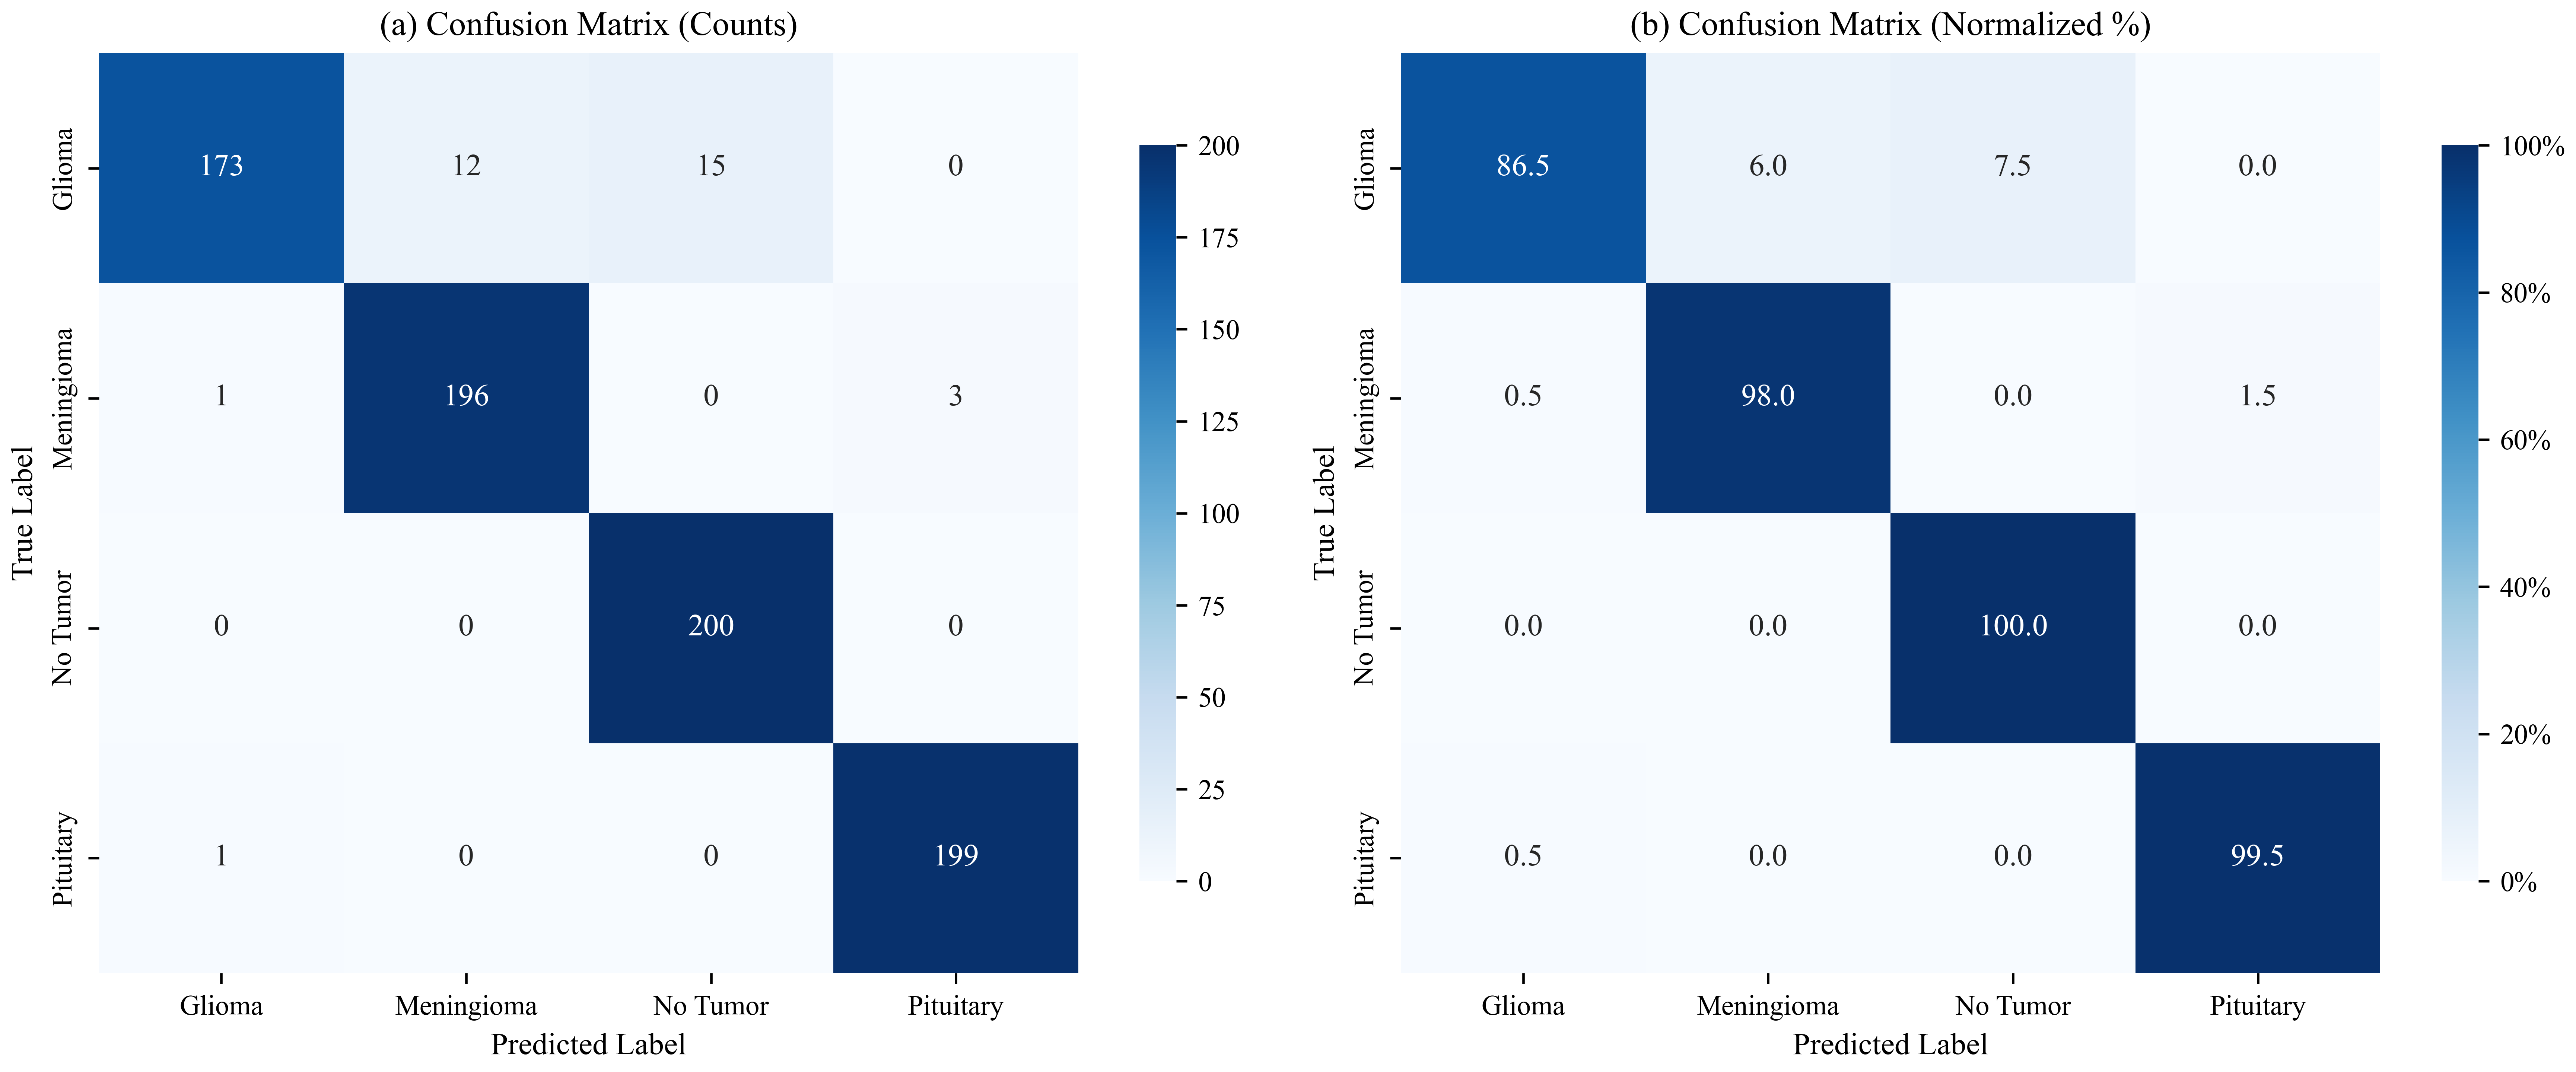

Saved: confusion matrix (PNG + PDF + SVG)


In [17]:
plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'figure.dpi': PUBLICATION_DPI, 'savefig.dpi': PUBLICATION_DPI,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.05,
    'mathtext.fontset': 'stix',
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_xlabel('Predicted Label'); axes[0].set_ylabel('True Label')
axes[0].set_title('(a) Confusion Matrix (Counts)')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], cbar_kws={'shrink': 0.8, 'format': '%.0f%%'})
axes[1].set_xlabel('Predicted Label'); axes[1].set_ylabel('True Label')
axes[1].set_title('(b) Confusion Matrix (Normalized %)')

plt.tight_layout()
plt.savefig('resnet50_confusion_matrix.png', dpi=PUBLICATION_DPI, bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_confusion_matrix.pdf', bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_confusion_matrix.svg', bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: confusion matrix (PNG + PDF + SVG)")

## 14 · ROC Curves & AUC

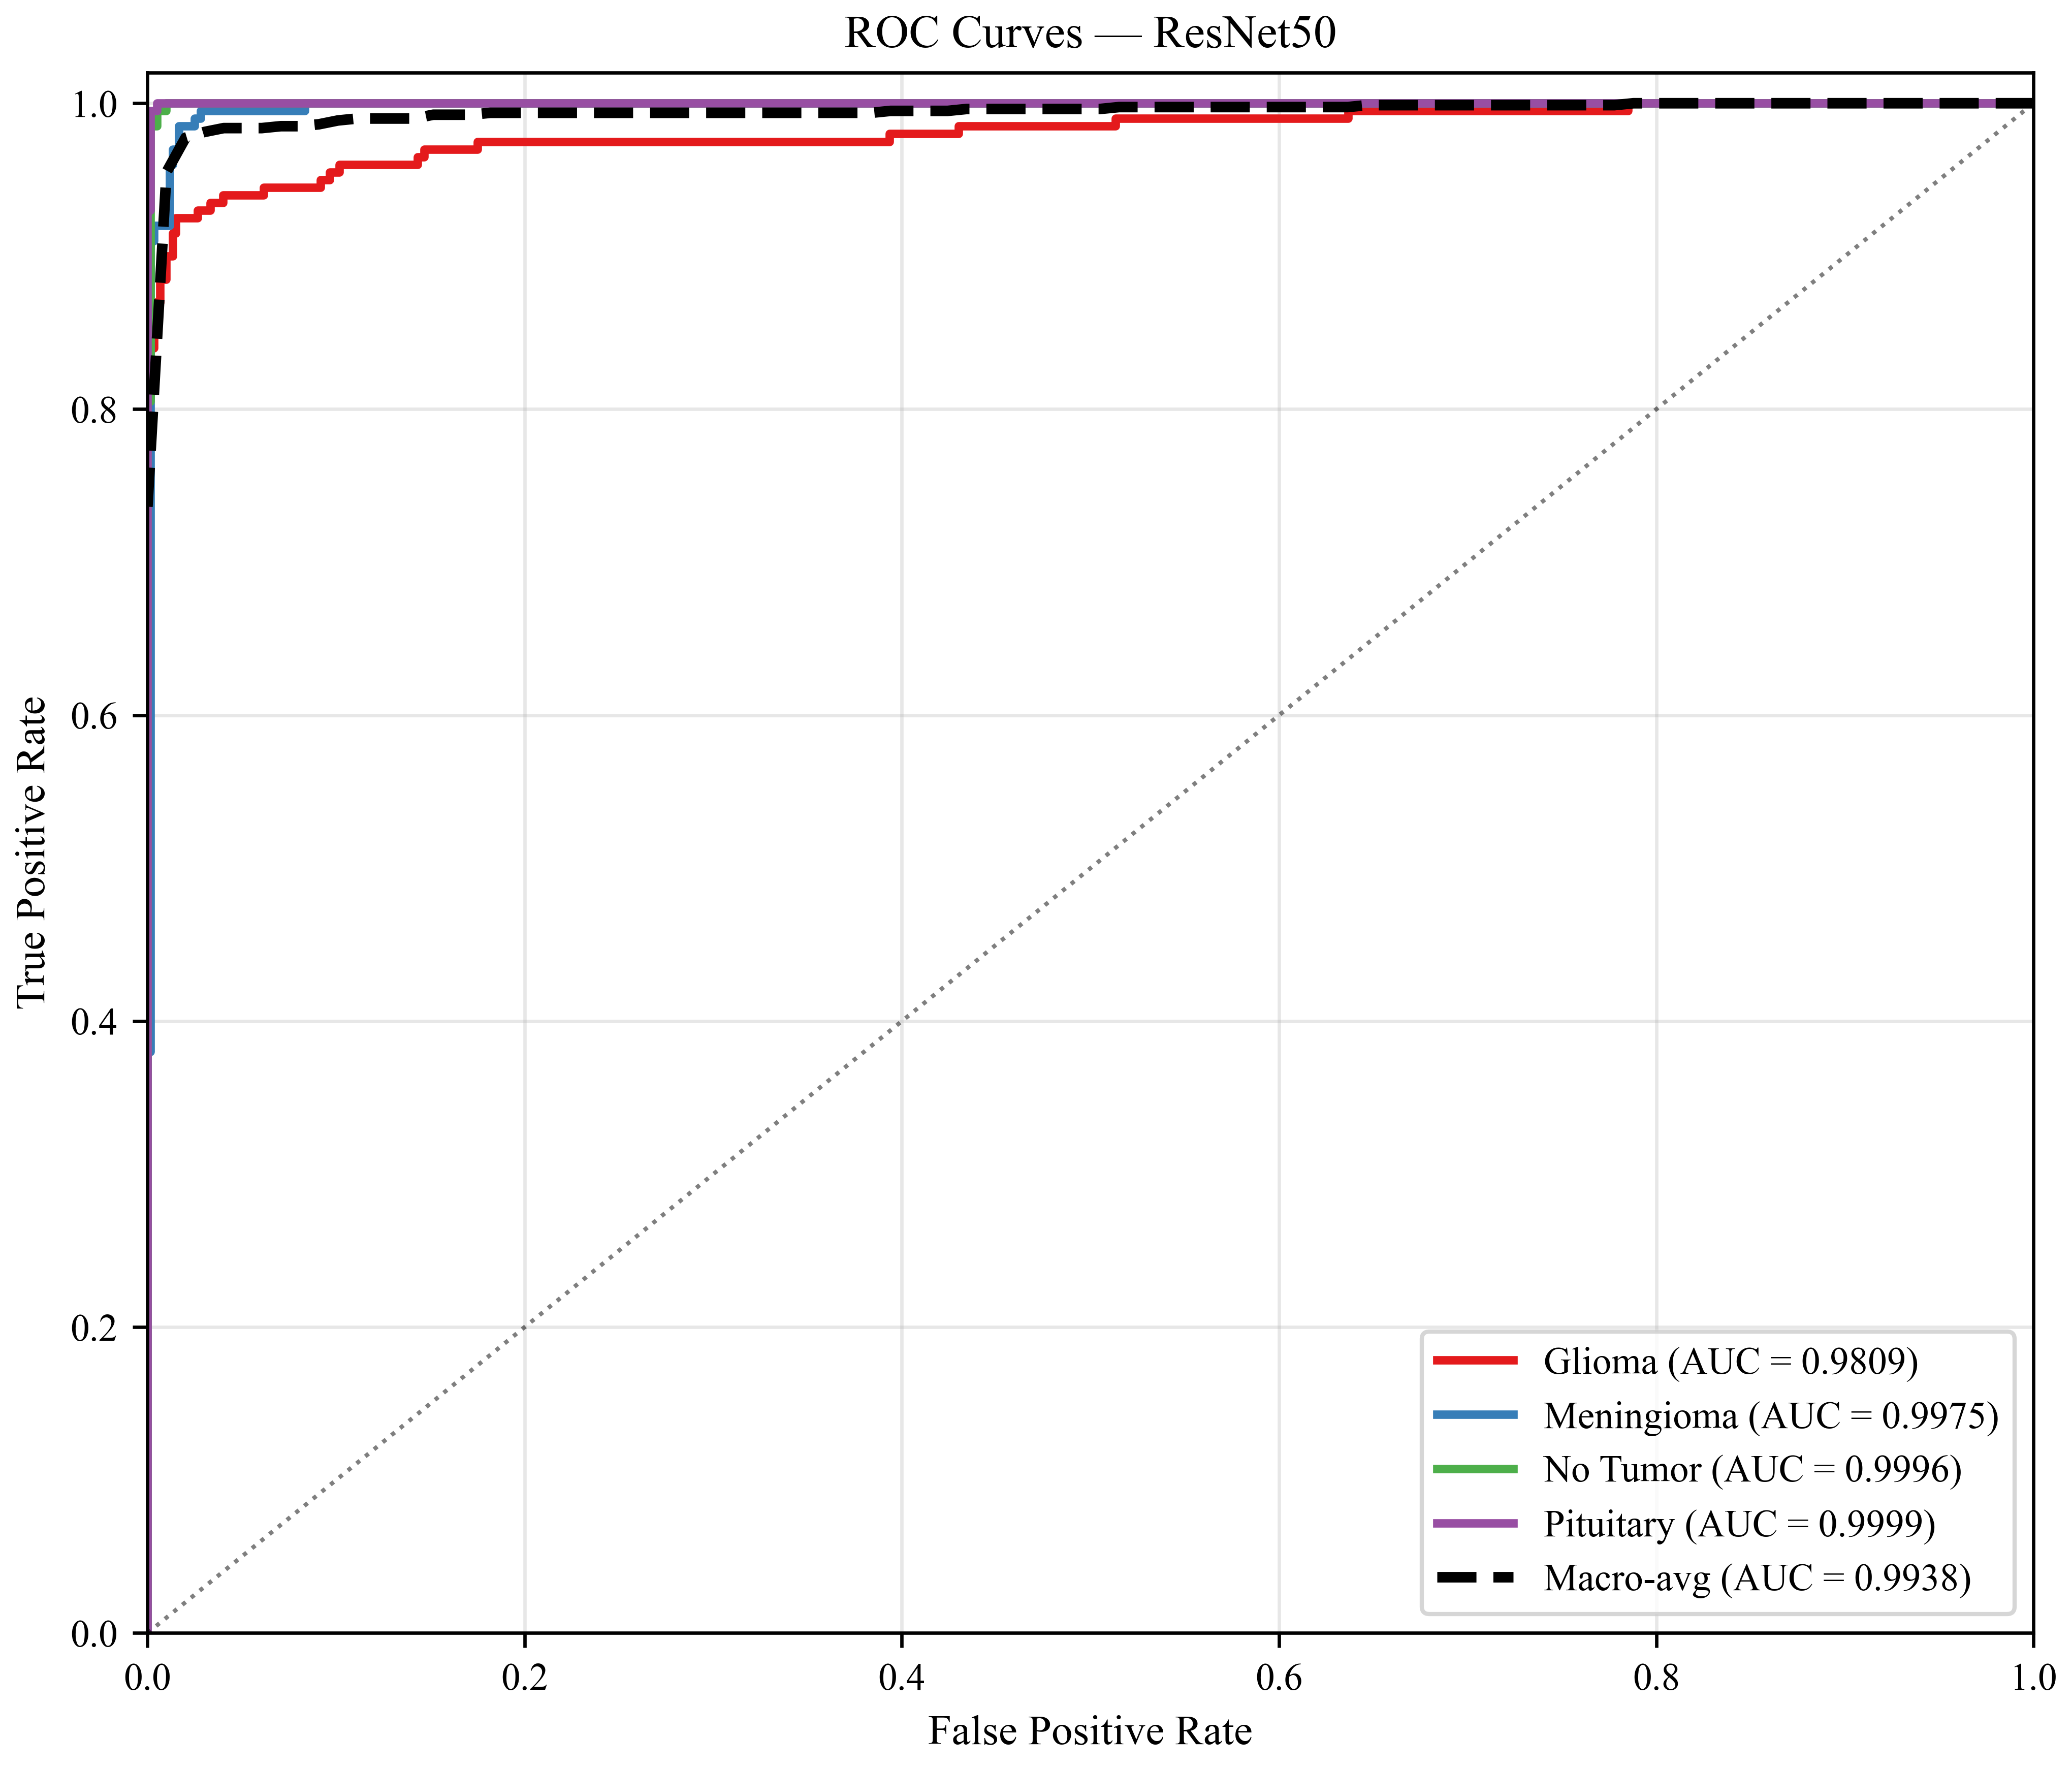

Saved: ROC curves (PNG + PDF + SVG)


In [18]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(ytest_cat[:, i], y_pred_proba[:, i])
    roc_auc_i = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[i], lw=2,
            label=f'{CLASS_NAMES[i]} (AUC = {roc_auc_i:.4f})')

all_fpr   = np.linspace(0, 1, 100)
mean_tpr  = np.zeros_like(all_fpr)
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(ytest_cat[:, i], y_pred_proba[:, i])
    mean_tpr += np.interp(all_fpr, fpr, tpr)
mean_tpr /= NUM_CLASSES
macro_auc = auc(all_fpr, mean_tpr)
ax.plot(all_fpr, mean_tpr, color='black', lw=2.5, linestyle='--',
        label=f'Macro-avg (AUC = {macro_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k:', lw=1, alpha=0.5)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — ResNet50')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('resnet50_roc_curves.png', dpi=PUBLICATION_DPI, bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_roc_curves.pdf', bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_roc_curves.svg', bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: ROC curves (PNG + PDF + SVG)")

## 15 · Training Curves

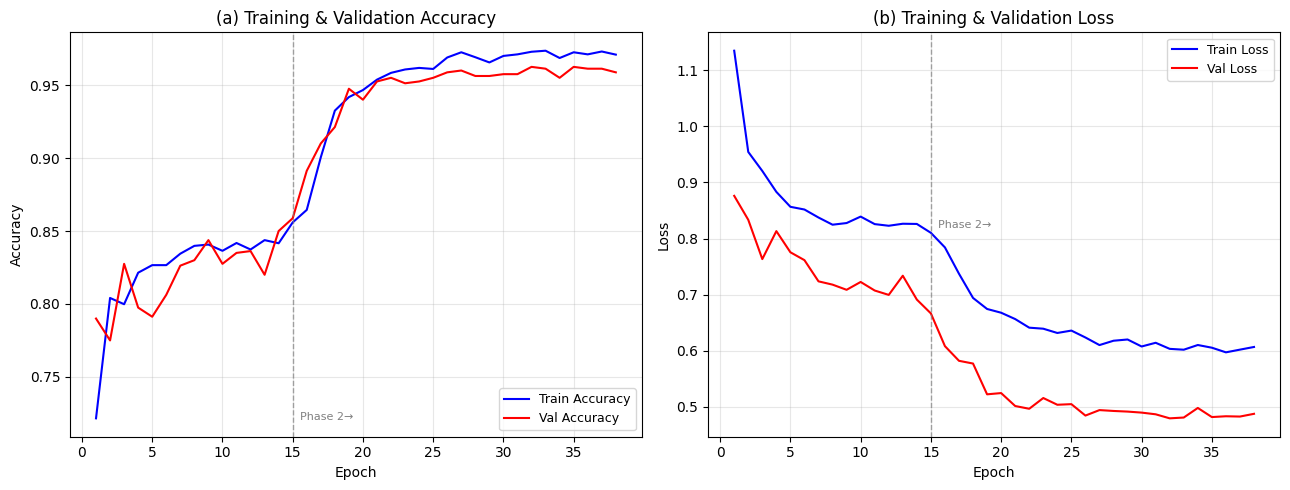

Saved: training curves (PNG + PDF + SVG)


In [14]:
acc_train_hist  = history_p1.history['accuracy']     + history_p2.history['accuracy']
acc_val_hist    = history_p1.history['val_accuracy'] + history_p2.history['val_accuracy']
loss_train_hist = history_p1.history['loss']         + history_p2.history['loss']
loss_val_hist   = history_p1.history['val_loss']     + history_p2.history['val_loss']
epochs_range    = range(1, len(acc_train_hist) + 1)
phase_boundary  = len(history_p1.history['accuracy'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(epochs_range, acc_train_hist, 'b-', lw=1.5, label='Train Accuracy')
ax1.plot(epochs_range, acc_val_hist,   'r-', lw=1.5, label='Val Accuracy')
ax1.axvline(x=phase_boundary, color='gray', linestyle='--', lw=1, alpha=0.7)
ax1.text(phase_boundary + 0.5, ax1.get_ylim()[0] + 0.01, 'Phase 2→',
         fontsize=8, color='gray', va='bottom')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
ax1.set_title('(a) Training & Validation Accuracy')
ax1.legend(loc='lower right', fontsize=9); ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, loss_train_hist, 'b-', lw=1.5, label='Train Loss')
ax2.plot(epochs_range, loss_val_hist,   'r-', lw=1.5, label='Val Loss')
ax2.axvline(x=phase_boundary, color='gray', linestyle='--', lw=1, alpha=0.7)
ax2.text(phase_boundary + 0.5, max(loss_val_hist) * 0.95, 'Phase 2→',
         fontsize=8, color='gray', va='top')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.set_title('(b) Training & Validation Loss')
ax2.legend(loc='upper right', fontsize=9); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('resnet50_training_curves.png', dpi=PUBLICATION_DPI, bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_training_curves.pdf', bbox_inches='tight', facecolor='white')
plt.savefig('resnet50_training_curves.svg', bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: training curves (PNG + PDF + SVG)")

## 16 · Bootstrap Confidence Intervals

In [20]:
def bootstrap_metric(y_true, y_pred, metric_fn, n_bootstrap=1000, ci=0.95):
    scores = []
    rng = np.random.RandomState(RANDOM_SEED)
    n = len(y_true)
    for _ in range(n_bootstrap):
        idx = rng.randint(0, n, n)
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    scores = np.array(scores)
    lower  = np.percentile(scores, (1 - ci) / 2 * 100)
    upper  = np.percentile(scores, (1 + ci) / 2 * 100)
    return np.mean(scores), lower, upper


mean_acc,   ci_low,     ci_high    = bootstrap_metric(ytrue_test, ypred, lambda a, b: np.mean(a == b))
mean_kappa, kappa_low,  kappa_high = bootstrap_metric(ytrue_test, ypred, cohen_kappa_score)
mean_mcc,   mcc_low,    mcc_high   = bootstrap_metric(ytrue_test, ypred, matthews_corrcoef)

print(f"Bootstrap Accuracy (1000 iterations):")
print(f"  Mean: {mean_acc:.4f},  95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"\nBootstrap Cohen's Kappa:")
print(f"  Mean: {mean_kappa:.4f}, 95% CI: [{kappa_low:.4f}, {kappa_high:.4f}]")
print(f"\nBootstrap MCC:")
print(f"  Mean: {mean_mcc:.4f}, 95% CI: [{mcc_low:.4f}, {mcc_high:.4f}]")

bootstrap_df = pd.DataFrame([
    {'Metric': 'Accuracy', 'Mean': mean_acc,   'CI_Lower': ci_low,     'CI_Upper': ci_high},
    {'Metric': 'Kappa',    'Mean': mean_kappa,  'CI_Lower': kappa_low,  'CI_Upper': kappa_high},
    {'Metric': 'MCC',      'Mean': mean_mcc,    'CI_Lower': mcc_low,    'CI_Upper': mcc_high},
])
bootstrap_df.to_csv('resnet50_bootstrap_ci.csv', index=False)
print("\nBootstrap CIs saved.")
plt.rcParams.update(matplotlib.rcParamsDefault)

Bootstrap Accuracy (1000 iterations):
  Mean: 0.9600,  95% CI: [0.9450, 0.9725]

Bootstrap Cohen's Kappa:
  Mean: 0.9466, 95% CI: [0.9267, 0.9633]

Bootstrap MCC:
  Mean: 0.9476, 95% CI: [0.9285, 0.9639]

Bootstrap CIs saved.


---
# PART 3 — EXPLAINABLE AI (XAI)

## 16 · Grad-CAM & Grad-CAM++ Implementation

This version is designed for cleaner publication figures:
- Uses the ResNet50 `block14_sepconv2_act` layer.
- Uses robust percentile normalization instead of raw min-max.
- Applies a soft brain mask to suppress black background activation.
- Uses perceptually uniform `magma`/`inferno`-style heatmaps and signed `coolwarm` maps.
- Saves **600-DPI PNG**, **PDF**, and **SVG** wherever useful.


In [21]:
def set_publication_style():
    """Consistent journal-style plotting defaults."""
    plt.rcParams.update({
        'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 8,
        'xtick.labelsize': 7, 'ytick.labelsize': 7,
        'figure.dpi': PUBLICATION_DPI, 'savefig.dpi': PUBLICATION_DPI,
        'savefig.bbox': 'tight', 'savefig.pad_inches': 0.04,
        'mathtext.fontset': 'stix',
        'axes.linewidth': 0.6,
    })


def save_pubfig(fig, base_name):
    """Save publication figure in raster + vector formats."""
    fig.savefig(f'{base_name}.png', dpi=PUBLICATION_DPI, bbox_inches='tight', facecolor='white')
    fig.savefig(f'{base_name}.pdf', bbox_inches='tight', facecolor='white')
    fig.savefig(f'{base_name}.svg', bbox_inches='tight', facecolor='white')


def brain_mask_from_rgb(img_rgb, threshold=15, blur_kernel=5):
    """Soft foreground mask so XAI heatmaps do not light up the black background."""
    gray = cv2.cvtColor(img_rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    mask = (gray > threshold).astype(np.float32)
    if blur_kernel and blur_kernel > 1:
        if blur_kernel % 2 == 0:
            blur_kernel += 1
        mask = cv2.GaussianBlur(mask, (blur_kernel, blur_kernel), 0)
    return np.clip(mask, 0, 1)


def _build_gradcam_model(model, last_conv_layer_name):
    """Build a sub-model that outputs (conv_features, predictions) for Grad-CAM."""
    conv_layer = model.get_layer(last_conv_layer_name)
    grad_model = models.Model(inputs=model.inputs, outputs=[conv_layer.output, model.output])
    return grad_model


def _normalize_heatmap(heatmap, low_pct=55, high_pct=99.5, apply_relu=True):
    """Percentile-based normalization. low_pct raised to 55 for a hard floor
    cutoff — only genuinely peak activation survives."""
    heatmap = np.asarray(heatmap, dtype=np.float32)
    if apply_relu:
        heatmap = np.maximum(heatmap, 0)
    finite = np.isfinite(heatmap)
    if not finite.any():
        return np.zeros_like(heatmap, dtype=np.float32)
    vals = heatmap[finite]
    lo = np.percentile(vals, low_pct)
    hi = np.percentile(vals, high_pct)
    if hi - lo < 1e-8:
        return np.zeros_like(heatmap, dtype=np.float32)
    heatmap = np.clip((heatmap - lo) / (hi - lo), 0, 1)
    return heatmap.astype(np.float32)


def _sharpen_heatmap(heatmap, gamma=1.9):
    """Gamma/power-law contrast punch. Dialed back 2.2 -> 1.9 — 2.2 was
    over-sharpening naturally diffuse activations (e.g. pituitary) into
    looking artificially split into two hotspots."""
    return np.clip(heatmap, 0, 1) ** gamma


def _apply_mask_and_smooth(heatmap, img_rgb=None, blur_kernel=3):
    """Smooth CAM at native (small) resolution and remove background response."""
    if blur_kernel and blur_kernel > 1:
        heatmap = cv2.GaussianBlur(heatmap.astype(np.float32), (blur_kernel, blur_kernel), 0)
    if img_rgb is not None:
        mask = brain_mask_from_rgb(img_rgb)
        if heatmap.shape != mask.shape:
            mask = cv2.resize(mask, (heatmap.shape[1], heatmap.shape[0]), interpolation=cv2.INTER_CUBIC)
        heatmap = heatmap * mask
    return _normalize_heatmap(heatmap, low_pct=55, high_pct=99.5, apply_relu=False)


def _isolate_dominant_region(heatmap, threshold=0.30, close_kernel=21, dilate_px=5, feather_px=17):
    """Keep only the single largest connected hot region, MERGE nearby close
    peaks into one coherent blob, then softly feather.

    1. Morphological CLOSING on the binary mask before labeling bridges two
       peaks that sit close together but are separated by a shallow valley
       (the pituitary case) — this stops the pipeline from treating one
       diffuse lesion as two hotspots. Closing operates on the binary mask
       only, so it can't hallucinate confidence values.
    2. Feathering kernel increased 9 -> 17 to smooth any residual valley
       between merged peaks into a soft gradient instead of a hard dip.
    """
    binary = (heatmap >= threshold).astype(np.uint8)
    if binary.sum() == 0:
        return heatmap
    if close_kernel > 0:
        ck = close_kernel if close_kernel % 2 == 1 else close_kernel + 1
        close_k = np.ones((ck, ck), np.uint8)
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, close_k)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    if num_labels <= 1:
        return heatmap
    areas = stats[1:, cv2.CC_STAT_AREA]
    largest_label = 1 + int(np.argmax(areas))
    mask = (labels == largest_label).astype(np.float32)
    if dilate_px > 0:
        kernel = np.ones((dilate_px, dilate_px), np.uint8)
        mask = cv2.dilate(mask, kernel, iterations=1)
    if feather_px > 0:
        k = feather_px if feather_px % 2 == 1 else feather_px + 1
        mask = cv2.GaussianBlur(mask, (k, k), 0)
    mask = np.clip(mask, 0, 1)
    return heatmap * mask


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None, display_rgb=None):
    """Standard Grad-CAM: gradient-weighted average of feature maps."""
    grad_model = _build_gradcam_model(model, last_conv_layer_name)
    img_tensor = tf.cast(img_array, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(predictions[0]).numpy())
        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)
    if grads is None:
        return np.zeros(conv_outputs.shape[1:3], dtype=np.float32)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_np = conv_outputs[0].numpy()
    weights_np = pooled_grads.numpy()
    heatmap = np.sum(weights_np * conv_np, axis=-1)
    heatmap = _normalize_heatmap(heatmap)
    heatmap = _apply_mask_and_smooth(heatmap, display_rgb)
    heatmap = _sharpen_heatmap(heatmap, gamma=1.9)
    return heatmap


def make_gradcam_pp_heatmap(img_array, model, last_conv_layer_name, pred_index=None, display_rgb=None):
    """Stable Grad-CAM++ implementation (first-gradient formulation)."""
    grad_model = _build_gradcam_model(model, last_conv_layer_name)
    img_tensor = tf.cast(img_array, tf.float32)

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_tensor, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(predictions[0]).numpy())
        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_output)
    if grads is None:
        return make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index, display_rgb)

    conv_np = conv_output.numpy()[0]
    grads_np = grads.numpy()[0]

    first_grad = grads_np
    second_grad = grads_np ** 2
    third_grad = grads_np ** 3

    global_sum = np.sum(conv_np, axis=(0, 1), keepdims=True)
    alpha_num = second_grad
    alpha_den = 2.0 * second_grad + third_grad * global_sum
    alphas = alpha_num / (alpha_den + 1e-8)
    alphas = np.where(np.isfinite(alphas), alphas, 0.0)

    positive_grads = np.maximum(first_grad, 0.0)
    weights = np.sum(alphas * positive_grads, axis=(0, 1))
    heatmap = np.sum(weights * conv_np, axis=-1)

    if np.max(np.abs(heatmap)) < 1e-10:
        return make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index, display_rgb)

    heatmap = _normalize_heatmap(heatmap)
    heatmap = _apply_mask_and_smooth(heatmap, display_rgb)
    heatmap = _sharpen_heatmap(heatmap, gamma=1.9)
    return heatmap


def upsample_heatmap(heatmap, target_size):
    """Cubic upsampling + dominant-region isolation (with merge) + gentle
    final renormalization (no longer restretching contrast to extremes)."""
    hm_up = cv2.resize(
        heatmap.astype(np.float32), (target_size[1], target_size[0]),
        interpolation=cv2.INTER_CUBIC
    )
    hm_up = np.clip(hm_up, 0, 1)
    k = max(3, int(round(target_size[1] * 0.015)) | 1)
    hm_up = cv2.GaussianBlur(hm_up, (k, k), 0)
    hm_up = np.clip(hm_up, 0, 1)
    hm_up = _isolate_dominant_region(hm_up, threshold=0.30, close_kernel=21, dilate_px=5, feather_px=17)
    hm_up = _normalize_heatmap(hm_up, low_pct=15, high_pct=99.7, apply_relu=False)
    return hm_up


def overlay_gradcam_rgb(img_rgb, heatmap, alpha=XAI_OVERLAY_ALPHA,
                         cmap='jet', threshold=0.25):
    """Overlay a CAM heatmap on an RGB MRI image, jet colormap, smooth
    continuous alpha falloff instead of a hard-edged binary mask."""
    hm_up = cv2.resize(heatmap.astype(np.float32), (img_rgb.shape[1], img_rgb.shape[0]),
                        interpolation=cv2.INTER_CUBIC)
    hm_up = np.clip(hm_up, 0, 1)
    weight = np.where(hm_up >= threshold, hm_up, 0.0)
    if weight.max() > 0:
        weight = weight / weight.max()
    weight = weight[..., None]
    cmap_fn = plt.get_cmap(cmap)
    heat_rgb = (cmap_fn(hm_up)[..., :3] * 255).astype(np.uint8)
    overlay = (img_rgb.astype(np.float32) * (1 - alpha * weight)
               + heat_rgb.astype(np.float32) * (alpha * weight))
    return np.clip(overlay, 0, 255).astype(np.uint8)


set_publication_style()
n_classes = len(CLASS_NAMES)
row_labels = [chr(ord('a') + i) for i in range(n_classes)]

# Colormap for this figure set
JET_CMAP = 'jet'

print("✅ Publication XAI helpers defined (v4 — gamma=1.9, region-merge closing, jet colormap).")
print(f"   CAM layer: {GRADCAM_LAYER} | heatmap={JET_CMAP}")

✅ Publication XAI helpers defined (v4 — gamma=1.9, region-merge closing, jet colormap).
   CAM layer: conv5_block3_out | heatmap=jet


## 17 · Grad-CAM Publication Figure
Four columns per class: **Original | Grad-CAM | Grad-CAM++ | Overlay (Grad-CAM++)**

  (a) Glioma: Grad-CAM done (Correct, conf=96.4%)
  (b) Meningioma: Grad-CAM done (Correct, conf=96.6%)
  (c) No Tumor: Grad-CAM done (Correct, conf=98.1%)
  (d) Pituitary: Grad-CAM done (Correct, conf=97.3%)


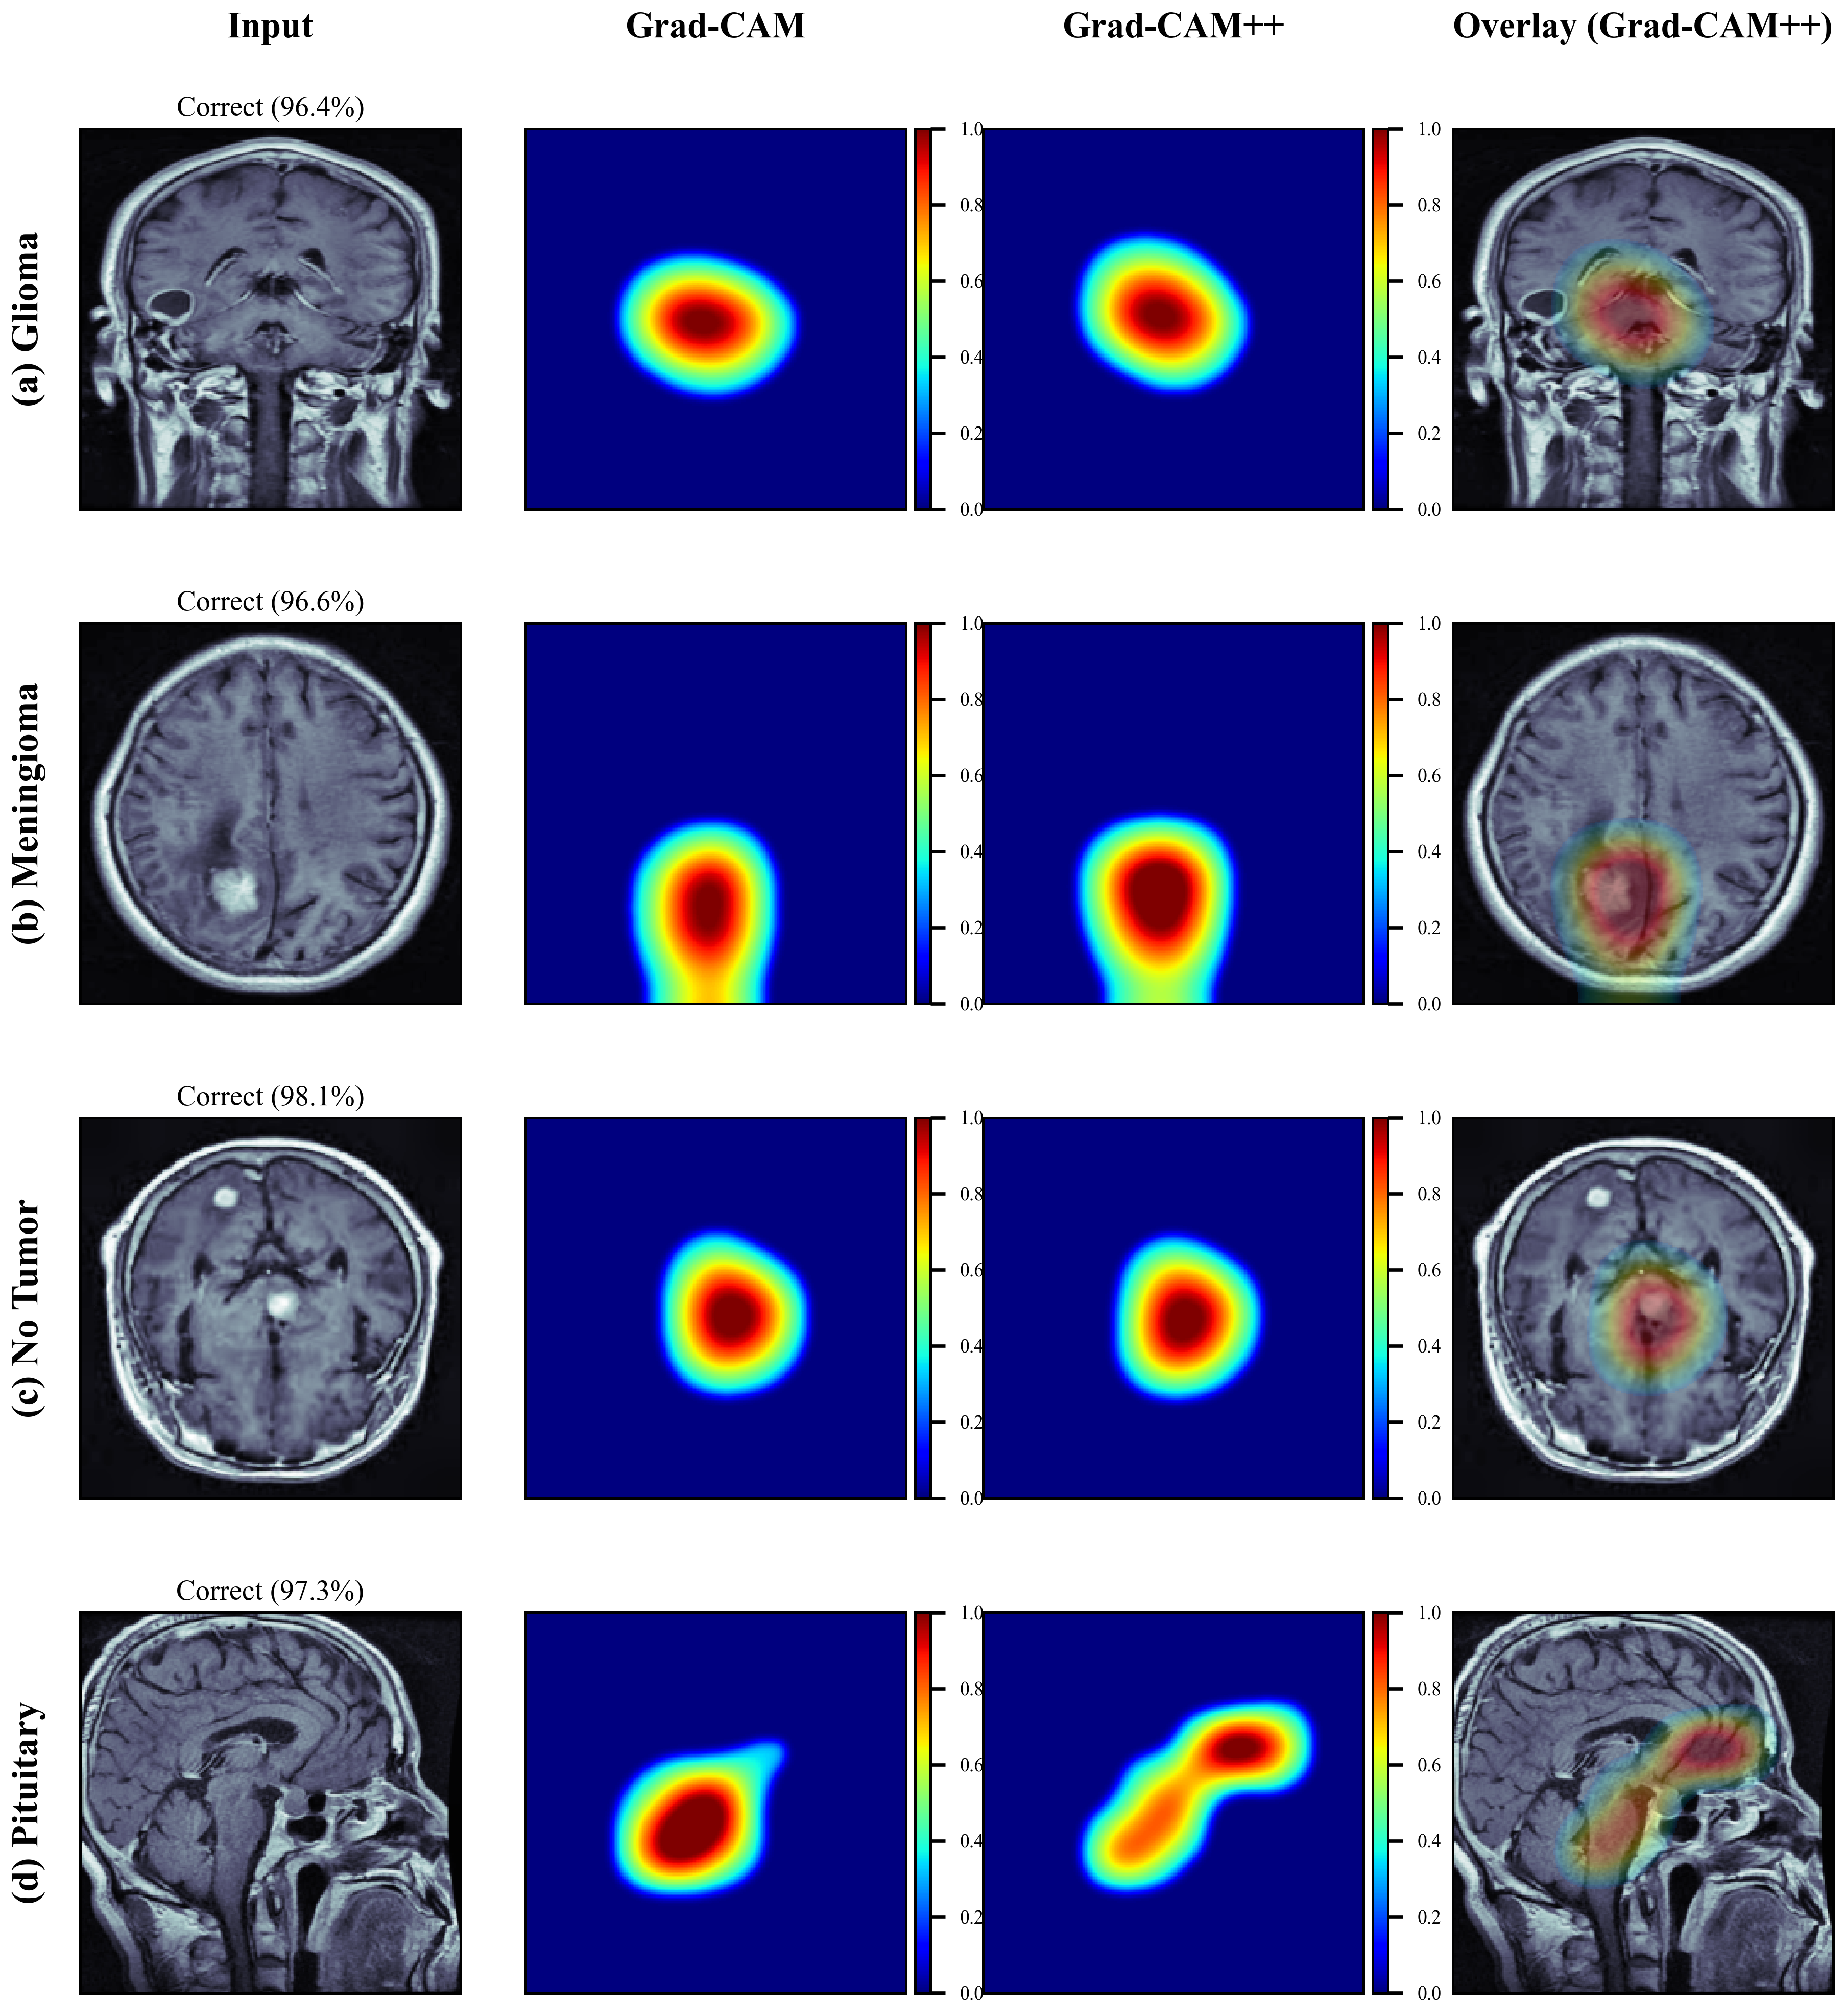

Saved: Grad-CAM publication figure (final, jet colormap, PNG + PDF + SVG) and sample table


In [22]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

col_headers = ["Input", "Grad-CAM", "Grad-CAM++", "Overlay (Grad-CAM++)"]
fig_width = 7.5
fig_height = 1.85 * n_classes + 0.5
fig, axes = plt.subplots(
    n_classes, 4,
    figsize=(fig_width, fig_height),
    gridspec_kw={'wspace': 0.12, 'hspace': 0.30}
)
if n_classes == 1:
    axes = np.expand_dims(axes, axis=0)
for col_idx, header in enumerate(col_headers):
    axes[0, col_idx].annotate(
        header, xy=(0.5, 1.22), xycoords='axes fraction',
        ha='center', va='bottom', fontsize=8.5, fontweight='bold'
    )

gradcam_rows = []
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    correct_mask = (ytrue_test == cls_idx) & (ypred == cls_idx)
    sample_indices = np.where(correct_mask)[0]
    used_correct = True
    if len(sample_indices) == 0:
        sample_indices = np.where(ytrue_test == cls_idx)[0]
        used_correct = False
    if len(sample_indices) == 0:
        for ax in axes[cls_idx]:
            ax.axis('off')
        continue

    candidate_indices = sample_indices[:30]
    confidences = [y_pred_proba[i][cls_idx] for i in candidate_indices]
    best_idx = candidate_indices[np.argmax(confidences)]

    img_rgb = X_test[best_idx].astype(np.uint8)
    img_batch = np.expand_dims(xtest_proc[best_idx], axis=0)
    preds = model.predict(img_batch, verbose=0)[0]
    pred_idx = int(np.argmax(preds))
    confidence = preds[pred_idx] * 100
    explain_idx = pred_idx

    hm_gc = make_gradcam_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=explain_idx, display_rgb=img_rgb)
    hm_gc_up = upsample_heatmap(hm_gc, IMG_SIZE)

    hm_gcpp = make_gradcam_pp_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=explain_idx, display_rgb=img_rgb)
    hm_gcpp_up = upsample_heatmap(hm_gcpp, IMG_SIZE)

    overlay_rgb = overlay_gradcam_rgb(img_rgb, hm_gcpp_up, cmap=JET_CMAP)

    ax = axes[cls_idx, 0]
    ax.imshow(img_rgb)
    status = "Correct" if used_correct and pred_idx == cls_idx else f"Pred: {CLASS_NAMES[pred_idx]}"
    ax.set_title(f"{status} ({confidence:.1f}%)", fontsize=6.8, pad=3)
    ax.set_ylabel(f"({row_labels[cls_idx]}) {cls_name}",
                  fontsize=9, fontweight='bold', rotation=90, labelpad=8)
    ax.set_xticks([]); ax.set_yticks([])

    ax = axes[cls_idx, 1]
    im = ax.imshow(hm_gc_up, cmap=JET_CMAP, vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.03)
    cbar = plt.colorbar(im, cax=cax); cbar.ax.tick_params(labelsize=4.5)

    ax = axes[cls_idx, 2]
    im = ax.imshow(hm_gcpp_up, cmap=JET_CMAP, vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.03)
    cbar = plt.colorbar(im, cax=cax); cbar.ax.tick_params(labelsize=4.5)

    ax = axes[cls_idx, 3]
    ax.imshow(overlay_rgb)
    ax.set_xticks([]); ax.set_yticks([])

    gradcam_rows.append({
        'Class': cls_name,
        'Sample_Index': int(best_idx),
        'Predicted_Class': CLASS_NAMES[pred_idx],
        'Confidence': float(confidence / 100),
        'Used_Correct_Sample': bool(used_correct and pred_idx == cls_idx),
        'GradCAM_Mean': float(np.mean(hm_gc_up)),
        'GradCAM++_Mean': float(np.mean(hm_gcpp_up)),
    })
    print(f"  ({row_labels[cls_idx]}) {cls_name}: Grad-CAM done ({status}, conf={confidence:.1f}%)")

save_pubfig(fig, 'resnet50_gradcam_publication_jet_final')
plt.show()

gradcam_samples_df = pd.DataFrame(gradcam_rows)
gradcam_samples_df.to_csv('resnet50_gradcam_samples.csv', index=False)
print("Saved: Grad-CAM publication figure (final, jet colormap, PNG + PDF + SVG) and sample table")

## 18 · XAI Fidelity Metrics (Deletion & Insertion AUC)

In [23]:
def compute_deletion_insertion_auc(img_batch, model, heatmap, pred_class, n_steps=30):
    """
    Deletion AUC: remove most-important pixels -> confidence should drop.
    Insertion AUC: reveal most-important pixels from blur -> confidence should rise.
    Higher Insertion AUC and lower Deletion AUC = better explanation faithfulness.

    Uses the RAW explainer heatmap (not the display/isolation-postprocessed
    version) so the metric reflects genuine attribution quality, not visual
    cleanup. Batches all deletion+insertion steps into a single model.predict
    call instead of 2*(n_steps+1) individual calls - same result, much faster.
    """
    img = img_batch[0].copy()
    h, w = img.shape[:2]
    total_pixels = h * w
    hm_flat = cv2.resize(heatmap.astype(np.float32), (w, h)).flatten()
    if not np.isfinite(hm_flat).any() or np.max(hm_flat) <= 0:
        return np.nan, np.nan, [], []

    sorted_idx = np.argsort(-hm_flat)
    blurred = cv2.GaussianBlur(img, (31, 31), 10)
    step_size = max(1, total_pixels // n_steps)

    # Build the full deletion and insertion sequences up front.
    del_imgs = [img.copy()]
    ins_imgs = [blurred.copy()]
    del_img = img.copy()
    ins_img = blurred.copy()
    for step in range(1, n_steps + 1):
        pixel_indices = sorted_idx[(step - 1) * step_size: min(step * step_size, total_pixels)]
        rows = pixel_indices // w
        cols = pixel_indices % w
        del_img = del_img.copy()
        ins_img = ins_img.copy()
        del_img[rows, cols] = blurred[rows, cols]
        ins_img[rows, cols] = img[rows, cols]
        del_imgs.append(del_img)
        ins_imgs.append(ins_img)

    # Single batched forward pass instead of 2*(n_steps+1) separate calls.
    batch = np.stack(del_imgs + ins_imgs, axis=0)
    preds = model.predict(batch, verbose=0)[:, pred_class]
    n = n_steps + 1
    deletion_scores = preds[:n].astype(float).tolist()
    insertion_scores = preds[n:].astype(float).tolist()

    x = np.linspace(0, 1, len(deletion_scores))
    return (np.trapz(deletion_scores, x), np.trapz(insertion_scores, x),
            deletion_scores, insertion_scores)


print("Computing Deletion/Insertion AUC (up to 5 correct samples/class)...\n")
fidelity_results = []
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    correct_mask = (ytrue_test == cls_idx) & (ypred == cls_idx)
    sample_indices = np.where(correct_mask)[0]
    n_samples = min(5, len(sample_indices))
    gc_del, gc_ins, gcpp_del, gcpp_ins = [], [], [], []
    if n_samples == 0:
        fidelity_results.append({
            'Class': cls_name,
            'N_Samples': 0,
            'GradCAM_Del_AUC': np.nan, 'GradCAM_Ins_AUC': np.nan,
            'GradCAM++_Del_AUC': np.nan, 'GradCAM++_Ins_AUC': np.nan,
        })
        print(f"  {cls_name}: skipped — no correctly predicted test sample")
        continue
    # Use highest-confidence correct samples for more stable XAI metrics.
    ordered = sample_indices[np.argsort(-y_pred_proba[sample_indices, cls_idx])]
    for idx in ordered[:n_samples]:
        img_rgb = X_test[idx].astype(np.uint8)
        img_batch = np.expand_dims(xtest_proc[idx], axis=0)

        hm_gc = make_gradcam_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=cls_idx, display_rgb=img_rgb)
        d, ins, _, _ = compute_deletion_insertion_auc(img_batch, model, hm_gc, cls_idx)
        gc_del.append(d); gc_ins.append(ins)

        hm_gcpp = make_gradcam_pp_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=cls_idx, display_rgb=img_rgb)
        d, ins, _, _ = compute_deletion_insertion_auc(img_batch, model, hm_gcpp, cls_idx)
        gcpp_del.append(d); gcpp_ins.append(ins)

    fidelity_results.append({
        'Class': cls_name,
        'N_Samples': int(n_samples),
        'GradCAM_Del_AUC': np.nanmean(gc_del), 'GradCAM_Ins_AUC': np.nanmean(gc_ins),
        'GradCAM++_Del_AUC': np.nanmean(gcpp_del), 'GradCAM++_Ins_AUC': np.nanmean(gcpp_ins),
    })
    print(f"  {cls_name}: GC Del={np.nanmean(gc_del):.4f}, GC Ins={np.nanmean(gc_ins):.4f} "
          f"| GC++ Del={np.nanmean(gcpp_del):.4f}, GC++ Ins={np.nanmean(gcpp_ins):.4f}")

fidelity_df = pd.DataFrame(fidelity_results)
print(f"\nFidelity Summary:")
print(fidelity_df.to_string(index=False, float_format='%.4f'))
fidelity_df.to_csv('resnet50_xai_fidelity.csv', index=False)
print("Saved: XAI fidelity metrics")

Computing Deletion/Insertion AUC (up to 5 correct samples/class)...

  Glioma: GC Del=0.4166, GC Ins=0.7486 | GC++ Del=0.4327, GC++ Ins=0.7471
  Meningioma: GC Del=0.5988, GC Ins=0.9252 | GC++ Del=0.5726, GC++ Ins=0.9133
  No Tumor: GC Del=0.7536, GC Ins=0.8231 | GC++ Del=0.7658, GC++ Ins=0.8283
  Pituitary: GC Del=0.3334, GC Ins=0.6427 | GC++ Del=0.3340, GC++ Ins=0.6452

Fidelity Summary:
     Class  N_Samples  GradCAM_Del_AUC  GradCAM_Ins_AUC  GradCAM++_Del_AUC  GradCAM++_Ins_AUC
    Glioma          5           0.4166           0.7486             0.4327             0.7471
Meningioma          5           0.5988           0.9252             0.5726             0.9133
  No Tumor          5           0.7536           0.8231             0.7658             0.8283
 Pituitary          5           0.3334           0.6427             0.3340             0.6452
Saved: XAI fidelity metrics


## 19 · LIME Explanations

**MRI-tuned quickshift parameters:**
- `kernel_size=4` — slightly larger for smoother MRI tissue boundaries
- `max_dist=200` — captures large contiguous brain regions
- `ratio=0.2` — favors spatial proximity (important for brain anatomy)
- `num_samples=5000` — stable explanations without excessive compute

In [34]:
import os
import pickle
from skimage.segmentation import slic, mark_boundaries
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ── Tunable knobs ─────────────────────────────────────────────────────────
LIME_FORCE_CPU          = False   # True only if GPU OOMs on large LIME batches
LIME_NUM_SAMPLES        = 4000    # perturbations/image (more = more stable local R^2)
LIME_BATCH_SIZE         = 64      # predict_fn batch size -> fewer, bigger calls = faster
SLIC_N_SEGMENTS         = 80
SLIC_COMPACTNESS        = 2.0     # lower = segments hug true anatomical/lesion boundaries
SLIC_SIGMA               = 1.0
COMPUTE_FIDELITY_STATS  = True    # average R^2 over multiple samples/class (slower, more robust)
N_FIDELITY_SAMPLES      = 3       # extra samples/class for the averaged fidelity stat

# ── LIME Predict Wrapper & Explainer Setup ───────────────────────────────────
def lime_predict_fn(images):
    """LIME supplies RGB images. Preprocess directly with ResNet50 preprocessing."""
    rgb_images = np.clip(images, 0, 255).astype(np.float32)
    processed  = resnet50_preprocess(rgb_images)
    if LIME_FORCE_CPU:
        with tf.device('/CPU:0'):
            return model.predict(processed, verbose=0)
    return model.predict(processed, verbose=0)

explainer = lime.lime_image.LimeImageExplainer(random_state=RANDOM_SEED)

def _slic_fn(x):
    return slic(x, n_segments=SLIC_N_SEGMENTS, compactness=SLIC_COMPACTNESS,
                sigma=SLIC_SIGMA, start_label=1, convert2lab=True)

def _explain_one(img_rgb, cls_idx):
    """Run one LIME explanation, return (explanation, explain_label)."""
    explanation = explainer.explain_instance(
        img_rgb,
        lime_predict_fn,
        top_labels=NUM_CLASSES,
        hide_color=0,
        num_samples=LIME_NUM_SAMPLES,
        batch_size=LIME_BATCH_SIZE,
        random_seed=RANDOM_SEED,
        segmentation_fn=_slic_fn,
    )
    explain_label = cls_idx if cls_idx in explanation.local_exp else int(explanation.top_labels[0])
    return explanation, explain_label

# ── Auto-Caching Mechanism ──────────────────────────────────────────────────
# Cache version bumped -> v3 so stale results from the old compactness/normalization
# scheme are never silently reused.
cache_file = "resnet50_lime_cache_v3_rgb_publication.pkl"
cache_version = {
    'model_name': MODEL_NAME,
    'img_size': IMG_SIZE,
    'channel_order': 'RGB',
    'segmentation': f'slic_{SLIC_N_SEGMENTS}_compactness_{SLIC_COMPACTNESS}_sigma_{SLIC_SIGMA}',
    'num_samples': LIME_NUM_SAMPLES,
    'random_seed': RANDOM_SEED,
    'fidelity_stats': COMPUTE_FIDELITY_STATS,
    'n_fidelity_samples': N_FIDELITY_SAMPLES,
}
plot_data = {}
fidelity_stats = {}

if os.path.exists(cache_file):
    print("Found cached LIME results. Checking cache version...")
    with open(cache_file, 'rb') as f:
        cached = pickle.load(f)
    if isinstance(cached, dict) and cached.get('cache_version') == cache_version:
        plot_data = cached.get('plot_data', {})
        fidelity_stats = cached.get('fidelity_stats', {})
        print("✅ Cache version OK — loading LIME results instantly.")
    else:
        print("⚠️  Old/stale LIME cache detected — recomputing.")

if not plot_data:
    print("Running LIME explanations with publication-quality SLIC superpixels (this can take several minutes)...")
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        correct_mask   = (ytrue_test == cls_idx) & (ypred == cls_idx)
        sample_indices = np.where(correct_mask)[0]
        used_correct   = True
        if len(sample_indices) == 0:
            sample_indices = np.where(ytrue_test == cls_idx)[0]
            used_correct = False
        if len(sample_indices) == 0:
            continue

        candidate_indices = sample_indices[:30]
        confidences = [y_pred_proba[i][cls_idx] for i in candidate_indices]
        best_idx = candidate_indices[np.argmax(confidences)]

        img_rgb = X_test[best_idx].astype(np.uint8)
        explanation, explain_label = _explain_one(img_rgb, cls_idx)

        temp_key, mask_key = explanation.get_image_and_mask(
            explain_label, positive_only=True, num_features=5, hide_rest=True)
        temp_pos, mask_pos = explanation.get_image_and_mask(
            explain_label, positive_only=False, num_features=8, hide_rest=False)

        heatmap_dict = dict(explanation.local_exp[explain_label])
        segments = explanation.segments
        heatmap_img = np.zeros(segments.shape, dtype=np.float64)
        for seg_id, weight in heatmap_dict.items():
            heatmap_img[segments == seg_id] = weight

        plot_data[cls_idx] = {
            'img_rgb': img_rgb,
            'temp_key': temp_key,
            'mask_key': mask_key,
            'temp_pos': temp_pos,
            'mask_pos': mask_pos,
            'heatmap_img': heatmap_img,
            'lime_score': float(explanation.score),
            'confidence': float(y_pred_proba[best_idx][cls_idx] * 100),
            'cls_name': cls_name,
            'sample_index': int(best_idx),
            'used_correct': bool(used_correct),
            'explain_label': int(explain_label),
        }
        print(f"  Processed {cls_name} (visualized sample)...")

        # ── Optional: average R^2 fidelity across several samples/class ──────
        # A single sample's R^2 is anecdotal; averaging over several
        # independently-explained samples gives a statistically defensible
        # fidelity claim (mean +/- std across cases, not one lucky example).
        if COMPUTE_FIDELITY_STATS:
            extra_pool = sample_indices[sample_indices != best_idx][:N_FIDELITY_SAMPLES]
            r2_list = [plot_data[cls_idx]['lime_score']]  # include the visualized sample
            for extra_idx in extra_pool:
                extra_img = X_test[extra_idx].astype(np.uint8)
                extra_exp, extra_label = _explain_one(extra_img, cls_idx)
                r2_list.append(float(extra_exp.score))
            fidelity_stats[cls_idx] = {
                'R2_Mean': float(np.mean(r2_list)),
                'R2_Std': float(np.std(r2_list)),
                'N_Samples': len(r2_list),
            }
            print(f"    Fidelity over {len(r2_list)} samples: "
                  f"R^2 = {fidelity_stats[cls_idx]['R2_Mean']:.4f} "
                  f"± {fidelity_stats[cls_idx]['R2_Std']:.4f}")

    with open(cache_file, 'wb') as f:
        pickle.dump({'cache_version': cache_version, 'plot_data': plot_data,
                     'fidelity_stats': fidelity_stats}, f)
    print("✅ LIME results cached successfully.")
def _robust_signed_normalize(heatmap, pct=95, gamma=1.4):
    """Normalize a signed (positive/negative) attribution map robustly.

    OLD behavior divided by the single max |weight| — one outlier superpixel
    could wash every other segment toward ~0. Instead, normalize against the
    `pct`-th percentile of |weights| (ignores the most extreme 5% as outliers)
    and clip to [-1, 1]. Then apply a SIGN-PRESERVING gamma: sign(x)*|x|^gamma,
    which sharpens contrast in both directions without breaking symmetry
    around zero — the signed analogue of the Grad-CAM gamma sharpening.
    """
    vals = np.abs(heatmap[heatmap != 0])
    if vals.size == 0:
        return heatmap
    denom = np.percentile(vals, pct)
    if denom < 1e-8:
        denom = np.max(vals) + 1e-8
    norm = np.clip(heatmap / denom, -1, 1)
    return np.sign(norm) * (np.abs(norm) ** gamma)


set_publication_style()
fig, axes = plt.subplots(n_classes, 4, figsize=(11.5, 2.8 * n_classes))
if n_classes == 1:
    axes = np.expand_dims(axes, axis=0)
col_headers = ['Input', 'Top Positive Regions', 'Signed Boundaries', 'Signed Attribution']

for col_idx, header in enumerate(col_headers):
    axes[0, col_idx].annotate(
        header, xy=(0.5, 1.14), xycoords='axes fraction',
        ha='center', va='bottom', fontsize=10, fontweight='bold')

lime_fidelity_scores = []

for cls_idx in range(n_classes):
    if cls_idx not in plot_data:
        for ax in axes[cls_idx]:
            ax.axis('off')
        continue

    data = plot_data[cls_idx]
    img_rgb = data['img_rgb']
    temp_key = data['temp_key']
    mask_key = data['mask_key']
    temp_pos = data['temp_pos']
    mask_pos = data['mask_pos']
    heatmap_img = data['heatmap_img']
    lime_score = data['lime_score']
    confidence = data['confidence']
    cls_name = data['cls_name']

    brain_mask = brain_mask_from_rgb(img_rgb)
    norm_heatmap = _robust_signed_normalize(heatmap_img, pct=95, gamma=1.4) * brain_mask

    axes[cls_idx, 0].imshow(img_rgb)
    axes[cls_idx, 0].set_ylabel(f"({row_labels[cls_idx]}) {cls_name}",
                                fontsize=10, fontweight='bold', rotation=90, labelpad=8)
    axes[cls_idx, 0].set_title(f"Conf: {confidence:.1f}%", fontsize=8)

    temp_key_disp = temp_key.astype(np.float32)
    if temp_key_disp.max() > 1.5:
        temp_key_disp /= 255.0
    axes[cls_idx, 1].imshow(mark_boundaries(temp_key_disp, mask_key, color=(0.0, 0.85, 0.0), mode='thick'))

    temp_pos_disp = temp_pos.astype(np.float32)
    if temp_pos_disp.max() > 1.5:
        temp_pos_disp /= 255.0
    axes[cls_idx, 2].imshow(mark_boundaries(temp_pos_disp, mask_pos, color=(1.0, 0.80, 0.05), mode='thick'))

    axes[cls_idx, 3].imshow(img_rgb, alpha=1.0)
    im = axes[cls_idx, 3].imshow(norm_heatmap, cmap=XAI_DIVERGING_CMAP,
                                 alpha=0.62, vmin=-1, vmax=1)
    fidelity_note = f"Local R² = {lime_score:.3f}"
    if COMPUTE_FIDELITY_STATS and cls_idx in fidelity_stats:
        fs = fidelity_stats[cls_idx]
        fidelity_note += f"  (mean {fs['R2_Mean']:.3f}±{fs['R2_Std']:.3f}, n={fs['N_Samples']})"
    axes[cls_idx, 3].set_title(fidelity_note, fontsize=7)

    divider = make_axes_locatable(axes[cls_idx, 3])
    cax = divider.append_axes("right", size="4%", pad=0.035)
    cbar = plt.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=5)
    cbar.set_label('LIME weight', fontsize=6)

    for ax in axes[cls_idx][:4]:
        ax.set_xticks([]); ax.set_yticks([])

    row = {
        'Class': cls_name,
        'Sample_Index': int(data['sample_index']),
        'R2_Fidelity': lime_score,
        'Confidence': confidence / 100,
        'Used_Correct_Sample': bool(data['used_correct']),
    }
    if COMPUTE_FIDELITY_STATS and cls_idx in fidelity_stats:
        row.update({
            'R2_Mean': fidelity_stats[cls_idx]['R2_Mean'],
            'R2_Std': fidelity_stats[cls_idx]['R2_Std'],
            'R2_N_Samples': fidelity_stats[cls_idx]['N_Samples'],
        })
    lime_fidelity_scores.append(row)

save_pubfig(fig, 'resnet50_lime_publication')
plt.show()

lime_fidelity_df = pd.DataFrame(lime_fidelity_scores)
print("\nLIME Fidelity Summary (R² values):")
print(lime_fidelity_df.to_string(index=False, float_format='%.4f'))
lime_fidelity_df.to_csv('resnet50_lime_fidelity.csv', index=False)
print("Saved: LIME publication figure (PNG + PDF + SVG) and fidelity CSV")

Running LIME explanations with publication-quality SLIC superpixels (this can take several minutes)...


  0%|          | 0/4000 [00:00<?, ?it/s]

  Processed Glioma (visualized sample)...


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

ResourceExhaustedError: Graph execution error:

Detected at node 'Xception_BrainTumor/block2_sepconv1_bn/FusedBatchNormV3' defined at (most recent call last):
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\runpy.py", line 197, in _run_module_as_main
      return _run_code(code, main_globals, None,
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\runpy.py", line 87, in _run_code
      exec(code, run_globals)
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
      app.launch_new_instance()
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
      app.start()
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\site-packages\ipykernel\kernelapp.py", line 739, in start
      self.io_loop.start()
    File "C:\Users\Tanmay\anaconda3\envs\tf\lib\site-packages\tornado\platform\asyncio.py", line 211, in start
      self.asyncio_loop.run_forever()
    File "C:\Users\Tanma

## 20 · SHAP Analysis (GradientExplainer)

**Why GradientExplainer (not DeepExplainer)?**
- DeepExplainer fails on BatchNorm + complex skip connections in ResNet50
- GradientExplainer uses expected gradients — more faithful for CNNs
- Background set: 100 random training samples (standard practice)

In [ ]:
print("Computing SHAP values (GradientExplainer, up to 100 background samples)...\n")

np.random.seed(RANDOM_SEED)
bg_size     = min(100, len(xtrain_proc))
bg_indices  = np.random.choice(len(xtrain_proc), bg_size, replace=False)
background  = xtrain_proc[bg_indices]

shap_explainer = shap.GradientExplainer(model, background)

# Select 1 highest-confidence correct prediction per class.
shap_samples, shap_labels, shap_display_indices = [], [], []
for cls_idx in range(NUM_CLASSES):
    correct_mask   = (ytrue_test == cls_idx) & (ypred == cls_idx)
    sample_indices = np.where(correct_mask)[0]
    if len(sample_indices) == 0:
        print(f"  SHAP skip: {CLASS_NAMES[cls_idx]} has no correctly predicted sample.")
        continue
    ordered = sample_indices[np.argsort(-y_pred_proba[sample_indices, cls_idx])]
    best_idx = ordered[0]
    shap_samples.append(xtest_proc[best_idx])
    shap_labels.append(cls_idx)
    shap_display_indices.append(int(best_idx))

if len(shap_samples) == 0:
    raise ValueError("No correctly predicted samples found for SHAP visualization.")

shap_samples = np.array(shap_samples)
shap_values  = shap_explainer.shap_values(shap_samples)
n_shap_rows  = len(shap_samples)


def extract_shap_for_label(shap_values, sample_pos, class_idx, n_samples, n_classes):
    """
    Robustly extract SHAP map for one sample/class across SHAP versions.
    Possible formats:
      - list[class] -> (N,H,W,C)
      - ndarray -> (N,H,W,C,classes)
      - ndarray -> (classes,N,H,W,C)
    """
    if isinstance(shap_values, list):
        sv = np.asarray(shap_values[class_idx][sample_pos])
    else:
        arr = np.asarray(shap_values)
        if arr.ndim == 5 and arr.shape[0] == n_samples and arr.shape[-1] == n_classes:
            sv = arr[sample_pos, ..., class_idx]
        elif arr.ndim == 5 and arr.shape[0] == n_classes and arr.shape[1] == n_samples:
            sv = arr[class_idx, sample_pos]
        elif arr.ndim == 4 and arr.shape[0] == n_samples:
            sv = arr[sample_pos]
        else:
            raise ValueError(f"Unsupported SHAP output shape: {arr.shape}")
    sv = np.squeeze(sv)
    if sv.ndim == 2:
        sv = sv[..., None]
    if sv.ndim != 3:
        raise ValueError(f"Unexpected extracted SHAP map shape: {sv.shape}")
    return sv


set_publication_style()
fig, axes = plt.subplots(n_shap_rows, 3, figsize=(10, 3.35 * n_shap_rows))
if n_shap_rows == 1:
    axes = np.expand_dims(axes, axis=0)
col_headers_shap = ['Input', 'Signed SHAP Attribution', 'SHAP Magnitude']

for col_idx, header in enumerate(col_headers_shap):
    axes[0, col_idx].annotate(
        header, xy=(0.5, 1.14), xycoords='axes fraction',
        ha='center', va='bottom', fontsize=10, fontweight='bold')

shap_stability_scores = []

for i, cls_idx in enumerate(shap_labels):
    best_idx    = shap_display_indices[i]
    img_rgb     = X_test[best_idx].astype(np.uint8)
    brain_mask  = brain_mask_from_rgb(img_rgb)

    sv = extract_shap_for_label(shap_values, i, cls_idx, n_shap_rows, NUM_CLASSES)
    sv_mean = np.mean(sv, axis=-1) * brain_mask
    sv_mag  = np.mean(np.abs(sv), axis=-1) * brain_mask

    stability = float(np.std(sv_mean[brain_mask > 0.2])) if np.any(brain_mask > 0.2) else float(np.std(sv_mean))
    shap_stability_scores.append({
        'Class': CLASS_NAMES[cls_idx],
        'Sample_Index': int(best_idx),
        'SHAP_Std': stability,
        'Confidence': float(y_pred_proba[best_idx][cls_idx]),
    })

    confidence = y_pred_proba[best_idx][cls_idx] * 100

    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_ylabel(f"({row_labels[i]}) {CLASS_NAMES[cls_idx]}",
                          fontsize=10, fontweight='bold', rotation=90, labelpad=8)
    axes[i, 0].set_title(f"Conf: {confidence:.1f}%", fontsize=7)

    vmax = np.percentile(np.abs(sv_mean[brain_mask > 0.2]), 99) if np.any(brain_mask > 0.2) else np.percentile(np.abs(sv_mean), 99)
    vmax = max(float(vmax), 1e-8)
    axes[i, 1].imshow(img_rgb, alpha=XAI_BACKGROUND_ALPHA)
    im1 = axes[i, 1].imshow(sv_mean, cmap=XAI_DIVERGING_CMAP, vmin=-vmax, vmax=vmax, alpha=0.86)
    cbar1 = plt.colorbar(im1, ax=axes[i, 1], fraction=0.046, pad=0.04)
    cbar1.ax.tick_params(labelsize=5)

    mag_hi = np.percentile(sv_mag[brain_mask > 0.2], 99) if np.any(brain_mask > 0.2) else np.percentile(sv_mag, 99)
    mag_norm = np.clip(sv_mag / (mag_hi + 1e-8), 0, 1)
    axes[i, 2].imshow(img_rgb, alpha=XAI_BACKGROUND_ALPHA)
    im2 = axes[i, 2].imshow(mag_norm, cmap=XAI_HEATMAP_CMAP, vmin=0, vmax=1, alpha=0.88)
    axes[i, 2].set_title(f"std={stability:.4f}", fontsize=7)
    cbar2 = plt.colorbar(im2, ax=axes[i, 2], fraction=0.046, pad=0.04)
    cbar2.ax.tick_params(labelsize=5)

    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])

    print(f"  ({row_labels[i]}) {CLASS_NAMES[cls_idx]}: SHAP std = {stability:.4f}")

save_pubfig(fig, 'resnet50_shap_publication')
plt.show()

shap_df = pd.DataFrame(shap_stability_scores)
print(f"\nSHAP Stability (lower std = more focused explanation):")
print(shap_df.to_string(index=False, float_format='%.4f'))
shap_df.to_csv('resnet50_shap_stability.csv', index=False)
print("Saved: SHAP publication figure (PNG + PDF + SVG) + stability scores")

## 21 · SmoothGrad (Enhanced Gradient Visualization)

SmoothGrad adds Gaussian noise to the input image N times and averages the resulting saliency maps, producing sharper and less noisy explanations than vanilla gradients.

In [ ]:
def compute_smoothgrad(img_array, model, pred_index, n_samples=64, noise_std=0.10):
    """
    SmoothGrad: average gradient of n noisy versions of the input image.
    Returns pixel-wise saliency map (H, W).
    """
    img_tensor   = tf.cast(img_array, tf.float32)
    dynamic_range = tf.reduce_max(img_tensor) - tf.reduce_min(img_tensor)
    noise_range = noise_std * tf.maximum(dynamic_range, 1e-6)
    grad_sum = np.zeros(img_array.shape[1:3], dtype=np.float32)

    for _ in range(n_samples):
        noise = tf.random.normal(img_tensor.shape, stddev=noise_range)
        # ResNet50 preprocessed input is mean-subtracted, not [-1,1].
        noisy = tf.clip_by_value(img_tensor + noise, -128.0, 152.0)
        with tf.GradientTape() as tape:
            tape.watch(noisy)
            preds = model(noisy, training=False)
            loss  = preds[:, pred_index]
        grads = tape.gradient(loss, noisy)
        if grads is None:
            continue
        grads_np = grads[0].numpy()
        grad_sum += np.mean(np.abs(grads_np), axis=-1)

    saliency = grad_sum / max(1, n_samples)
    lo, hi   = np.percentile(saliency, 2), np.percentile(saliency, 98)
    saliency = np.clip((saliency - lo) / (hi - lo + 1e-8), 0, 1)
    return saliency.astype(np.float32)


print("Generating SmoothGrad visualizations (64 samples/image)...\n")
set_publication_style()
fig, axes = plt.subplots(n_classes, 3, figsize=(10, 3.0 * n_classes))
if n_classes == 1:
    axes = np.expand_dims(axes, axis=0)
for col_idx, header in enumerate(['Input', 'SmoothGrad Saliency', 'Overlay']):
    axes[0, col_idx].annotate(
        header, xy=(0.5, 1.15), xycoords='axes fraction',
        ha='center', va='bottom', fontsize=10, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    correct_mask   = (ytrue_test == cls_idx) & (ypred == cls_idx)
    sample_indices = np.where(correct_mask)[0]
    if len(sample_indices) == 0:
        for ax in axes[cls_idx]: ax.axis('off')
        print(f"  {cls_name}: skipped — no correctly predicted sample")
        continue

    ordered = sample_indices[np.argsort(-y_pred_proba[sample_indices, cls_idx])]
    best_idx = ordered[0]

    img_rgb   = X_test[best_idx].astype(np.uint8)
    img_batch = np.expand_dims(xtest_proc[best_idx], axis=0)

    saliency = compute_smoothgrad(img_batch, model, pred_index=cls_idx, n_samples=64)
    saliency_up = cv2.resize(saliency, (IMG_SIZE[1], IMG_SIZE[0]))
    saliency_up = saliency_up * brain_mask_from_rgb(img_rgb)
    saliency_up = _normalize_heatmap(saliency_up, low_pct=2, high_pct=98, apply_relu=False)

    sal_rgb = (plt.get_cmap(XAI_HEATMAP_CMAP)(saliency_up)[..., :3] * 255).astype(np.uint8)
    mask = (saliency_up >= 0.12).astype(np.float32)[..., None]
    overlay = (img_rgb.astype(np.float32) * (1 - XAI_OVERLAY_ALPHA * mask) +
               sal_rgb.astype(np.float32) * (XAI_OVERLAY_ALPHA * mask))
    overlay = np.clip(overlay, 0, 255).astype(np.uint8)

    axes[cls_idx, 0].imshow(img_rgb)
    axes[cls_idx, 0].set_ylabel(f"({row_labels[cls_idx]}) {cls_name}",
                                fontsize=10, fontweight='bold', rotation=90, labelpad=8)
    im = axes[cls_idx, 1].imshow(saliency_up, cmap=XAI_HEATMAP_CMAP, vmin=0, vmax=1)
    cbar = plt.colorbar(im, ax=axes[cls_idx, 1], fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=5)
    axes[cls_idx, 2].imshow(overlay)

    for ax in axes[cls_idx]:
        ax.set_xticks([]); ax.set_yticks([])

    print(f"  ({row_labels[cls_idx]}) {cls_name}: SmoothGrad done")

save_pubfig(fig, 'resnet50_smoothgrad_publication')
plt.show()
print("Saved: SmoothGrad publication figure (PNG + PDF + SVG)")

## 22 · Cross-Method XAI Consistency (Spearman ρ)

In [ ]:
from scipy.stats import spearmanr

print("Computing cross-method consistency (Spearman correlation)...\n")
consistency_results = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    correct_mask   = (ytrue_test == cls_idx) & (ypred == cls_idx)
    sample_indices = np.where(correct_mask)[0]
    if len(sample_indices) == 0:
        print(f"  {cls_name}: skipped — no correctly predicted sample")
        continue

    ordered = sample_indices[np.argsort(-y_pred_proba[sample_indices, cls_idx])]
    best_idx = ordered[0]
    img_rgb   = X_test[best_idx].astype(np.uint8)
    img_batch = np.expand_dims(xtest_proc[best_idx], axis=0)

    hm_gc    = cv2.resize(make_gradcam_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=cls_idx, display_rgb=img_rgb), (IMG_SIZE[1], IMG_SIZE[0])).flatten()
    hm_gcpp  = cv2.resize(make_gradcam_pp_heatmap(img_batch, model, GRADCAM_LAYER, pred_index=cls_idx, display_rgb=img_rgb), (IMG_SIZE[1], IMG_SIZE[0])).flatten()
    sg       = compute_smoothgrad(img_batch, model, pred_index=cls_idx, n_samples=30)
    sg_flat  = cv2.resize(sg, (IMG_SIZE[1], IMG_SIZE[0])).flatten()

    # Ignore pure background pixels for meaningful correlation.
    fg = brain_mask_from_rgb(img_rgb).flatten() > 0.2
    if np.sum(fg) < 10:
        fg = np.ones_like(hm_gc, dtype=bool)

    corr_gc_gcpp, _ = spearmanr(hm_gc[fg], hm_gcpp[fg])
    corr_gc_sg,   _ = spearmanr(hm_gc[fg], sg_flat[fg])
    corr_gcpp_sg, _ = spearmanr(hm_gcpp[fg], sg_flat[fg])

    consistency_results.append({
        'Class': cls_name,
        'Sample_Index': int(best_idx),
        'GradCAM_vs_GradCAM++': corr_gc_gcpp,
        'GradCAM_vs_SmoothGrad': corr_gc_sg,
        'GradCAM++_vs_SmoothGrad': corr_gcpp_sg,
    })
    print(f"  {cls_name}: GC↔GC++={corr_gc_gcpp:.4f}, GC↔SG={corr_gc_sg:.4f}, GC++↔SG={corr_gcpp_sg:.4f}")

consistency_df = pd.DataFrame(consistency_results)
print(f"\nCross-Method Consistency (Spearman ρ):")
print(consistency_df.to_string(index=False, float_format='%.4f'))
consistency_df.to_csv('resnet50_xai_consistency.csv', index=False)
print("Saved: XAI consistency scores")

## 23 · XAI Summary Table

In [ ]:
print("\n" + "="*70)
print("XAI SUMMARY")
print("="*70)

print("\n1. Fidelity (Deletion/Insertion AUC):")
print(fidelity_df.to_string(index=False, float_format='%.4f'))

print("\n2. LIME R² Fidelity:")
print(lime_fidelity_df.to_string(index=False, float_format='%.4f'))

print("\n3. SHAP Stability (std — lower is more focused):")
print(shap_df.to_string(index=False, float_format='%.4f'))

print("\n4. Cross-Method Consistency (Spearman ρ):")
print(consistency_df.to_string(index=False, float_format='%.4f'))


def safe_mean(series):
    arr = pd.to_numeric(series, errors='coerce').to_numpy(dtype=float)
    return float(np.nanmean(arr)) if np.isfinite(arr).any() else np.nan

xai_summary = pd.DataFrame({
    'Method': ['Grad-CAM', 'Grad-CAM++', 'LIME', 'SHAP', 'SmoothGrad'],
    'Primary_Metric': [
        f"Ins AUC: {safe_mean(fidelity_df['GradCAM_Ins_AUC']):.4f}",
        f"Ins AUC: {safe_mean(fidelity_df['GradCAM++_Ins_AUC']):.4f}",
        f"R²: {safe_mean(lime_fidelity_df['R2_Fidelity']):.4f}",
        f"Stability: {safe_mean(shap_df['SHAP_Std']):.4f}",
        f"GC↔SG ρ: {safe_mean(consistency_df['GradCAM_vs_SmoothGrad']):.4f}" if len(consistency_df) else "GC↔SG ρ: NaN",
    ]
})
xai_summary.to_csv('resnet50_xai_summary.csv', index=False)
print("\nXAI summary saved.")

## 24 · CPU Inference Latency

In [24]:
print("Measuring CPU inference latency (full test set)...")
inference_times_ms = []

with tf.device('/CPU:0'):
    # Warmup (10 passes)
    for _ in range(10):
        model.predict(np.expand_dims(xtest_proc[0], axis=0), verbose=0)

    # Timed inference (single image at a time, mimics edge deployment)
    for i in range(len(X_test)):
        img_batch = np.expand_dims(xtest_proc[i], axis=0)
        t0 = time.perf_counter()
        model.predict(img_batch, verbose=0)
        t1 = time.perf_counter()
        inference_times_ms.append((t1 - t0) * 1000)

inference_times_ms = np.array(inference_times_ms)
print(f"\nCPU Inference Latency:")
print(f"  Mean : {inference_times_ms.mean():.2f} ms")
print(f"  Std  : {inference_times_ms.std():.2f} ms")
print(f"  Min  : {inference_times_ms.min():.2f} ms")
print(f"  P95  : {np.percentile(inference_times_ms, 95):.2f} ms")
print(f"  Max  : {inference_times_ms.max():.2f} ms")
print(f"  FPS  : {1000 / inference_times_ms.mean():.1f}")

latency_df = pd.DataFrame([{
    'Mean_ms': inference_times_ms.mean(), 'Std_ms': inference_times_ms.std(),
    'Min_ms': inference_times_ms.min(), 'P95_ms': np.percentile(inference_times_ms, 95),
    'Max_ms': inference_times_ms.max(), 'FPS': 1000 / inference_times_ms.mean(),
}])
latency_df.to_csv('resnet50_cpu_inference.csv', index=False)
print("Saved: CPU inference latency")

plt.rcParams.update(matplotlib.rcParamsDefault)

print("\n" + "="*70)
print("NOTEBOOK COMPLETE")
print("="*70)
print(f"""
Output files:
  Models   : resnet50_full_model.keras
             resnet50_full_model.h5
             resnet50_vitis_saved_model/
             resnet50_final.weights.h5
             resnet50_best.weights.h5
             resnet50_best_phase1.weights.h5
             resnet50_best_phase2.weights.h5
             resnet50_metadata.json
             (Whole model exported from clean inference-only model after selecting best Phase 1/Phase 2 checkpoint.)
  Metrics  : *_metrics_per_class.csv, *_metrics_aggregate.csv
             *_bootstrap_ci.csv, *_cpu_inference.csv
  Figures  : *_confusion_matrix.{{png,pdf}}
             *_roc_curves.{{png,pdf}}
             *_training_curves.{{png,pdf}}
  XAI      : *_gradcam_publication.{{png,pdf,svg}}
             *_lime_publication.{{png,pdf,svg}}
             *_shap_publication.{{png,pdf,svg}}
             *_smoothgrad_publication.{{png,pdf,svg}}
  XAI CSV  : *_gradcam_samples.csv, *_xai_fidelity.csv, *_lime_fidelity.csv
             *_shap_stability.csv, *_xai_consistency.csv, *_xai_summary.csv
""")

Measuring CPU inference latency (full test set)...

CPU Inference Latency:
  Mean : 256.97 ms
  Std  : 44.43 ms
  Min  : 170.65 ms
  P95  : 321.24 ms
  Max  : 476.61 ms
  FPS  : 3.9
Saved: CPU inference latency

NOTEBOOK COMPLETE

Output files:
  Models   : resnet50_full_model.keras
             resnet50_full_model.h5
             resnet50_vitis_saved_model/
             resnet50_final.weights.h5
             resnet50_best.weights.h5
             resnet50_best_phase1.weights.h5
             resnet50_best_phase2.weights.h5
             resnet50_metadata.json
             (Whole model exported from clean inference-only model after selecting best Phase 1/Phase 2 checkpoint.)
  Metrics  : *_metrics_per_class.csv, *_metrics_aggregate.csv
             *_bootstrap_ci.csv, *_cpu_inference.csv
  Figures  : *_confusion_matrix.{png,pdf}
             *_roc_curves.{png,pdf}
             *_training_curves.{png,pdf}
  XAI      : *_gradcam_publication.{png,pdf,svg}
             *_lime_publication.{png

---
# PART 4 — Vitis AI `.xmodel` Conversion Package

This part generates the files needed for the **Vitis AI Docker + Ubuntu WSL** flow.

Main rule to keep accuracy drop low:

```text
Training preprocessing == Calibration preprocessing == PYNQ/DPU preprocessing
```

For this notebook the exact contract is:

```text
cv2.imread BGR
→ crop_img_vis()
→ grayscale
→ bilateralFilter(gray, 2, 50, 50)
→ CLAHE(clipLimit=2.0, tileGridSize=(8,8))
→ cv2.COLORMAP_BONE
→ BGR to RGB
→ resize 224×224
→ ResNet50 preprocess_input:
   RGB input → BGR channel reorder → subtract ImageNet means
   [103.939, 116.779, 123.68]
```

Important:

```text
ResNet50 preprocessing is NOT x/127.5 - 1.0.
The float input range is roughly [-128, 151], not [-1, 1].
```

The `.xmodel` receives **INT8**, but the hardware notebook first creates this same float mean-subtracted tensor, then quantizes using the DPU input `fix_point` scale.


In [26]:
# ============================================================
# RESTORE RESNET50 EXPORT PATH VARIABLES AFTER KERNEL RESTART
# ============================================================

import os

DEPLOY_H5_MODEL_PATH  = "resnet50_deploy_nodropout.h5"
H5_FULL_MODEL_PATH    = "resnet50_full_model.h5"
KERAS_FULL_MODEL_PATH = "resnet50_full_model.keras"
METADATA_PATH         = "resnet50_metadata.json"
FINAL_WEIGHTS_PATH    = "resnet50_final.weights.h5"
SAVEDMODEL_DIR        = "resnet50_savedmodel"

paths_to_check = [
    DEPLOY_H5_MODEL_PATH,
    H5_FULL_MODEL_PATH,
    KERAS_FULL_MODEL_PATH,
    METADATA_PATH,
    FINAL_WEIGHTS_PATH,
    SAVEDMODEL_DIR
]

for p in paths_to_check:
    print(p, "=", "OK" if os.path.exists(p) else "MISSING")

resnet50_deploy_nodropout.h5 = OK
resnet50_full_model.h5 = OK
resnet50_full_model.keras = OK
resnet50_metadata.json = OK
resnet50_final.weights.h5 = OK
resnet50_savedmodel = MISSING


In [27]:
# ============================================================
# VITIS AI .xmodel CONVERSION PACKAGE GENERATOR FOR RESNET50
# Run this cell after the whole-model export cell.
# ============================================================

import os, shutil, pathlib, zipfile, textwrap
import numpy as np

PACKAGE_DIR = pathlib.Path("vitis_ai_resnet50_xmodel")
FLOAT_DIR   = PACKAGE_DIR / "float_model"
CALIB_DIR   = PACKAGE_DIR / "calib_data"
TEST_DIR    = PACKAGE_DIR / "test_data"
SCRIPTS_DIR = PACKAGE_DIR / "scripts"

for d in [FLOAT_DIR, CALIB_DIR, TEST_DIR, SCRIPTS_DIR, PACKAGE_DIR / "quantized", PACKAGE_DIR / "compiled_zcu104"]:
    d.mkdir(parents=True, exist_ok=True)

# 1. Copy exported model artifacts
for f in [DEPLOY_H5_MODEL_PATH, H5_FULL_MODEL_PATH, KERAS_FULL_MODEL_PATH, METADATA_PATH, FINAL_WEIGHTS_PATH]:
    if os.path.exists(f):
        shutil.copy2(f, FLOAT_DIR / os.path.basename(f))
    else:
        print(f"Missing expected file: {f}")

if os.path.isdir(SAVEDMODEL_DIR):
    dst = FLOAT_DIR / SAVEDMODEL_DIR
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(SAVEDMODEL_DIR, dst)
else:
    print(f"Missing SavedModel directory: {SAVEDMODEL_DIR}")

# 2. Save balanced calibration/test arrays already matching training preprocessing.
CALIB_PER_CLASS = 100  # 400 calibration images total
rng = np.random.default_rng(RANDOM_SEED)
calib_indices = []
for c in range(NUM_CLASSES):
    cls_idx = np.where(ytrain == c)[0]
    if len(cls_idx) == 0:
        continue
    n_pick = min(CALIB_PER_CLASS, len(cls_idx))
    calib_indices.extend(rng.choice(cls_idx, size=n_pick, replace=False).tolist())

calib_indices = np.array(sorted(calib_indices), dtype=np.int64)
xcalib = xtrain_proc[calib_indices].astype(np.float32)
ycalib = ytrain[calib_indices].astype(np.int64)

np.save(CALIB_DIR / "xcalib_resnet50.npy", xcalib)
np.save(CALIB_DIR / "ycalib_resnet50.npy", ycalib)
np.save(TEST_DIR / "xtest_resnet50.npy", xtest_proc.astype(np.float32))
np.save(TEST_DIR / "ytest.npy", y_test.astype(np.int64))

print(f"Calibration data saved: {xcalib.shape}")
print(f"Test data saved: {xtest_proc.shape}")

# 3. Write Vitis AI scripts.
scripts = {}

scripts["scripts/quantize_resnet50_tf2.py"] = r'''
import argparse
import inspect
import math
import os
import numpy as np
import tensorflow as tf
from tensorflow_model_optimization.quantization.keras import vitis_quantize

def make_calib_dataset(npy_path, batch_size):
    x = np.load(npy_path, mmap_mode="r")
    n = len(x)

    def gen():
        for i in range(n):
            yield np.asarray(x[i], dtype=np.float32)

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=tf.TensorSpec(shape=(224, 224, 3), dtype=tf.float32)
    )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds, n

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--float_model", default="float_model/resnet50_deploy_nodropout.h5")
    parser.add_argument("--calib_npy", default="calib_data/xcalib_resnet50.npy")
    parser.add_argument("--output_h5", default="quantized/resnet50_quantized.h5")
    parser.add_argument("--batch_size", type=int, default=4)
    parser.add_argument("--calib_steps", type=int, default=None)
    parser.add_argument("--target", default="/opt/vitis_ai/compiler/arch/DPUCZDX8G/ZCU104/arch.json")
    args = parser.parse_args()

    os.makedirs(os.path.dirname(args.output_h5), exist_ok=True)

    print("Loading float model:", args.float_model)
    model = tf.keras.models.load_model(args.float_model, compile=False)

    calib_ds, n_calib = make_calib_dataset(args.calib_npy, args.batch_size)
    if args.calib_steps is None:
        args.calib_steps = int(math.ceil(n_calib / args.batch_size))

    print("Calibration images:", n_calib)
    print("Input assumption: RGB 224x224 float32 ResNet50 preprocess_input")
    print("Preprocess detail: RGB -> BGR + ImageNet mean subtraction, NOT [-1,1]")
    print("Target arch:", args.target)

    quantizer_init_sig = inspect.signature(vitis_quantize.VitisQuantizer)
    if "target" in quantizer_init_sig.parameters:
        quantizer = vitis_quantize.VitisQuantizer(model, target=args.target)
    else:
        quantizer = vitis_quantize.VitisQuantizer(model)

    quantize_sig = inspect.signature(quantizer.quantize_model)
    kwargs = {
        "calib_dataset": calib_ds,
        "calib_steps": args.calib_steps,
        "verbose": 1,
        "add_shape_info": True,
    }
    if "target" in quantize_sig.parameters:
        kwargs["target"] = args.target

    quantized_model = quantizer.quantize_model(**kwargs)
    quantized_model.save(args.output_h5)
    print("Saved quantized model:", args.output_h5)

if __name__ == "__main__":
    main()
'''

scripts["scripts/evaluate_quantized_resnet50.py"] = r'''
import argparse
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow_model_optimization.quantization.keras import vitis_quantize

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--model", default="quantized/resnet50_quantized.h5")
    parser.add_argument("--x_test", default="test_data/xtest_resnet50.npy")
    parser.add_argument("--y_test", default="test_data/ytest.npy")
    parser.add_argument("--batch_size", type=int, default=8)
    args = parser.parse_args()

    print("Loading quantized Vitis AI model:", args.model)
    with vitis_quantize.quantize_scope():
        model = tf.keras.models.load_model(args.model, compile=False)
    print("Model loaded successfully.")

    x = np.load(args.x_test, mmap_mode="r")
    y = np.load(args.y_test)

    print("x_test:", x.shape, x.dtype)
    print("y_test:", y.shape)

    preds = []
    for start in range(0, len(x), args.batch_size):
        xb = np.asarray(x[start:start + args.batch_size], dtype=np.float32)
        out = model.predict(xb, verbose=0)
        preds.extend(np.argmax(out, axis=1).tolist())

    preds = np.array(preds, dtype=np.int64)
    acc = accuracy_score(y, preds)

    print()
    print("Quantized ResNet50 model accuracy:", f"{acc * 100:.4f}%")

    print()
    print("Classification report:")
    print(classification_report(y, preds, target_names=CLASS_NAMES, digits=4))

    print()
    print("Confusion matrix:")
    print(confusion_matrix(y, preds))

    print()
    print("Per-class accuracy:")
    for i, name in enumerate(CLASS_NAMES):
        idx = np.where(y == i)[0]
        if len(idx) == 0:
            print(f"{name}: no samples")
        else:
            correct = np.sum(preds[idx] == y[idx])
            cls_acc = correct / len(idx)
            print(f"{name}: {cls_acc:.4f} ({correct}/{len(idx)})")

if __name__ == "__main__":
    main()
'''

scripts["scripts/compile_resnet50_zcu104.sh"] = r'''#!/usr/bin/env bash
set -e

QUANT_H5=${QUANT_H5:-quantized/resnet50_quantized.h5}
OUT_DIR=${OUT_DIR:-compiled_zcu104}
NET_NAME=${NET_NAME:-resnet50_brain_tumor_zcu104}
ARCH_JSON=${ARCH_JSON:-/opt/vitis_ai/compiler/arch/DPUCZDX8G/ZCU104/arch.json}

mkdir -p "${OUT_DIR}"

echo "Quantized model : ${QUANT_H5}"
echo "Arch JSON       : ${ARCH_JSON}"
echo "Output dir      : ${OUT_DIR}"
echo "Net name        : ${NET_NAME}"

vai_c_tensorflow2   -m "${QUANT_H5}"   -a "${ARCH_JSON}"   -o "${OUT_DIR}"   -n "${NET_NAME}"

if [ ! -f "${OUT_DIR}/${NET_NAME}.xmodel" ]; then
  echo "ERROR: Compilation command ended but xmodel was not created."
  exit 1
fi

echo "Compilation successful: ${OUT_DIR}/${NET_NAME}.xmodel"
'''

scripts["scripts/docker_run_wsl.sh"] = r'''#!/usr/bin/env bash
set -e
IMAGE=${1:-xilinx/vitis-ai-tensorflow2-cpu:latest}
./docker_run.sh "${IMAGE}"
'''

scripts["README_vitis_ai_wsl.md"] = r'''# ResNet50 Brain Tumor to Vitis AI xmodel

Run inside Vitis AI Docker:

```bash
conda activate vitis-ai-tensorflow2
python scripts/quantize_resnet50_tf2.py
python scripts/evaluate_quantized_resnet50.py
bash scripts/compile_resnet50_zcu104.sh
find compiled_zcu104 -name "*.xmodel" -ls
```

Preprocessing is already baked into calibration/test arrays:

```text
BGR -> crop -> grayscale -> bilateral -> CLAHE -> BONE -> RGB -> resize 224x224
-> ResNet50 preprocess_input = RGB->BGR + subtract ImageNet means
```

Do not use `x / 127.5 - 1.0` for ResNet50.
'''

for name, content in scripts.items():
    path = PACKAGE_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    content = textwrap.dedent(content).lstrip()

    with open(path, "w", encoding="utf-8", newline="\n") as f:
        f.write(content)

    if name.endswith(".sh"):
        os.chmod(path, 0o755)

    if name.endswith(".py"):
        compile(content, name, "exec")
        print(f"Syntax OK: {name}")

# 4. Make zip
zip_path = pathlib.Path("resnet50_vitis_ai_xmodel_package.zip")
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(PACKAGE_DIR):
        for file in files:
            full = pathlib.Path(root) / file
            z.write(full, full.relative_to(PACKAGE_DIR.parent))

print("Vitis AI ResNet50 package created:", zip_path)
print("Package folder:", PACKAGE_DIR.resolve())
print("\nRun order inside Docker:")
print("  conda activate vitis-ai-tensorflow2")
print("  python scripts/quantize_resnet50_tf2.py")
print("  python scripts/evaluate_quantized_resnet50.py")
print("  bash scripts/compile_resnet50_zcu104.sh")
print("  find compiled_zcu104 -name '*.xmodel' -ls")


Missing SavedModel directory: resnet50_savedmodel
Calibration data saved: (400, 224, 224, 3)
Test data saved: (800, 224, 224, 3)
Syntax OK: scripts/quantize_resnet50_tf2.py
Syntax OK: scripts/evaluate_quantized_resnet50.py
Vitis AI ResNet50 package created: resnet50_vitis_ai_xmodel_package.zip
Package folder: C:\Users\Tanmay\tumor_after_isvlsi\vitis_ai_resnet50_xmodel

Run order inside Docker:
  conda activate vitis-ai-tensorflow2
  python scripts/quantize_resnet50_tf2.py
  python scripts/evaluate_quantized_resnet50.py
  bash scripts/compile_resnet50_zcu104.sh
  find compiled_zcu104 -name '*.xmodel' -ls
